### __Лабораторна робота 3. Нейронні мережі для табличних даних, зображень і текстів__

##### __Датасет частини 1__: "Web page Phishing Detection Dataset"
##### __Посилання__: https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset
##### __Опис__: 11 430 URL-адрес із 87 числовими ознаками, по 5 715 легітимних і фішингових. Той самий датасет, що в лабораторних роботах 1 і 2.

##### __Датасет частини 2__: "Garbage Classification"
##### __Посилання__: https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification/data
##### __Опис__: 2 527 фотографій сміття у 6 класах: cardboard (403), glass (501), metal (410), paper (594), plastic (482), trash (137).

##### __Датасет частини 3__: "MovieLens Latest Datasets" (ml-latest-small)
##### __Посилання__: https://grouplens.org/datasets/movielens/latest/
##### __Опис__: теги користувачів до фільмів (`tags.csv`) та жанри фільмів (`movies.csv`). Та сама задача, що в частині 3 лабораторної роботи 2: за тегами визначити жанр (Comedy, Drama, Horror).

#### __Мета роботи__: Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

# Частина 1. Повнозв'язана нейронна мережа (MLP) для табличних даних

##### Постановка задачі

За 87 числовими ознаками веб-сторінки визначити, чи вона легітимна (0), чи фішингова (1). Це бінарна класифікація, але замість класичних алгоритмів тепер повнозв'язана нейронна мережа. Тестова вибірка формується тими самими параметрами, що в лабі 1, щоб порівняння було коректним.

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Subset

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

In [70]:
torch.manual_seed(10)
random.seed(10)
np.random.seed(10)

In [71]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


In [72]:
df = pd.read_csv('../lab1/dataset_phishing.csv')
print(df.shape)
print(df['status'].value_counts())
print(df.isnull().sum().sum())

(11430, 89)
status
legitimate    5715
phishing      5715
Name: count, dtype: int64
0


In [73]:
df = df.drop('url', axis=1)
df['status'] = LabelEncoder().fit_transform(df['status'])

X = df.drop('status', axis=1)
y = df['status']
print(X.shape, y.shape)

(11430, 87) (11430,)


##### Попередня обробка

Обробка повторює лабораторну роботу 1. Новим є те що потрібна третя, валідаційна, вибірка: мережа навчається поступово, і треба десь дивитися, на якій епосі зупинитися. Робити це по тесту не можна, бо тоді тест перестає бути незалежним (data leakage).

Тому спочатку відокремлюється 20% на тест (як у лабі 1), а від решти ще 20% на валідацію: 7 315 / 1 829 / 2 286 об'єктів.

In [74]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=10, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=10, stratify=y_train_full)

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts())

(7315, 87) (1829, 87) (2286, 87)
status
0    3658
1    3657
Name: count, dtype: int64


In [75]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

##### Масштабування

Для нейронної мережі масштабування обов'язкове. Якщо одна ознака має порядок мільйонів (`web_traffic`), а інша є 0 або 1, то сума на вході нейрона буде завеликою, функція активації потрапить у зону насичення, а її похідна стане близькою до нуля. Градієнт тоді теж прямує до нуля і ваги майже не оновлюються.

`fit` робиться лише на тренувальній вибірці.

In [76]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.long)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

print(X_train_t.shape, X_train_t.dtype)
print(y_train_t.shape, y_train_t.dtype)

torch.Size([7315, 87]) torch.float32
torch.Size([7315]) torch.int64


In [77]:
train_data = TensorDataset(X_train_t, y_train_t)
val_data = TensorDataset(X_val_t, y_val_t)
test_data = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

for xb, yb in train_loader:
    print(xb.shape, yb.shape)
    break

torch.Size([64, 87]) torch.Size([64])


##### Тензори та DataLoader

Ознаки мають тип `float32`, а мітки `long`, бо `CrossEntropyLoss` очікує номер класу. `TensorDataset` тримає ознаки та мітки в парі, `DataLoader` нарізає набір на батчі по 64.

Батчі потрібні, бо ваги оновлюються після кожного пакета, а не після кожного окремого об'єкта (це шумно) і не після всього датасету (це повільно).

In [78]:
num_input_feat = X_train_t.shape[1]
num_outputs = 2
print(num_input_feat, num_outputs)


class PhishingMLP(nn.Module):
    def __init__(self, hidden1, hidden2, p_drop):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_input_feat, hidden1),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(hidden2, num_outputs)
        )

    def forward(self, x):
        logits = self.net(x)
        return logits


model = PhishingMLP(64, 32, 0.0).to(device)
print(model)

87 2
PhishingMLP(
  (net): Sequential(
    (0): Linear(in_features=87, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [79]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable params:", num_params)

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape), param.numel())

Trainable params: 7778
net.0.weight (64, 87) 5568
net.0.bias (64,) 64
net.3.weight (32, 64) 2048
net.3.bias (32,) 32
net.6.weight (2, 32) 64
net.6.bias (2,) 2


##### Архітектура мережі

Мережа має три шари `nn.Linear`: 87 -> 64 -> 32 -> 2. Кожен нейрон такого шару отримує всі виходи попереднього шару, помножені на власні ваги, плюс зсув (bias).

Між лінійними шарами стоїть `nn.ReLU`, тобто max(0, x). Активація має бути нелінійною: інакше кілька лінійних шарів поспіль були б еквівалентні одному лінійному класифікатору. ReLU взято тому, що вона не насичується при x > 0 і швидко обчислюється.

`nn.Dropout(p)` під час навчання випадково вимикає частку p нейронів, що протидіє перенавчанню. Поки що `p_drop=0.0`: це базова модель, на якій буде видно перенавчання.

Останній шар має 2 виходи й без активації, тобто повертає логіти, бо `nn.CrossEntropyLoss` сама застосовує softmax. Параметрів: (87+1)*64 + (64+1)*32 + (32+1)*2 = 7 778.

In [80]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    train_loss = 0.0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(loader)

    return train_loss


def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()
    valid_loss = 0.0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            valid_loss += loss.item()

    valid_loss /= len(loader)

    return valid_loss


@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()
    total_correct = 0
    total_samples = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        preds = out.argmax(1)
        total_correct += (preds == y).sum().item()
        total_samples += y.size(0)

    return total_correct / total_samples


@torch.no_grad()
def predict_all(model, loader, device):
    model.eval()
    all_preds = []
    all_true = []

    for x, y in loader:
        x = x.to(device)
        out = model(x)
        all_preds += out.argmax(1).cpu().tolist()
        all_true += y.tolist()

    return all_true, all_preds


def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    epochs = range(1, len(train_loss) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, "bo", label="Training loss")
    plt.plot(epochs, val_loss, "b", label="Validation loss")
    plt.title(title + ": loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, "ro", label="Training accuracy")
    plt.plot(epochs, val_acc, "r", label="Validation accuracy")
    plt.title(title + ": accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.show()

##### Функції навчання та оцінювання

Ці функції використовуються в усіх трьох частинах роботи, тому визначені один раз.

`train_one_epoch` виконує один прохід по всіх тренувальних батчах, і для кожного робить п'ять дій:
1. `optimizer.zero_grad()` обнуляє градієнти, бо PyTorch їх накопичує.
2. `out = model(x)` прямий прохід, мережа видає логіти.
3. `loss = criterion(out, y)` обчислення втрати.
4. `loss.backward()` зворотне поширення помилки, рахуються градієнти.
5. `optimizer.step()` крок градієнтного спуску.

`evaluate_one_epoch` рахує ту саму втрату без навчання: `model.eval()` вимикає dropout і переводить BatchNorm на збережену статистику, а `torch.no_grad()` забороняє рахувати градієнти. Решта функцій рахують accuracy, збирають передбачення для `confusion_matrix` і малюють learning curves.

In [81]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

##### Функція втрат та оптимізатор

`nn.CrossEntropyLoss` застосовує softmax до логітів і бере мінус логарифм ймовірності правильного класу. Важливо, що вона реагує не лише на факт помилки, а й на впевненість мережі, тому для стеження за навчанням зручніша за accuracy.

`torch.optim.Adam` є адаптивним варіантом градієнтного спуску: він тримає для кожної ваги власний розмір кроку, тому збігається швидше за звичайний SGD і майже не потребує налаштування. `lr=1e-3` це стандартне значення, далі воно перевіряється при підборі гіперпараметрів.

In [82]:
n_epochs = 60

train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

for epoch in range(n_epochs):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss = evaluate_one_epoch(model, val_loader, criterion, device)
    train_acc = evaluate_accuracy(model, train_loader, device)
    val_acc = evaluate_accuracy(model, val_loader, device)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)

    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | train_acc={train_acc:.4f} | val_acc={val_acc:.4f}")

[01] train_loss=0.3431 | val_loss=0.1542 | train_acc=0.9427 | val_acc=0.9475
[02] train_loss=0.1444 | val_loss=0.1276 | train_acc=0.9552 | val_acc=0.9513
[03] train_loss=0.1254 | val_loss=0.1073 | train_acc=0.9605 | val_acc=0.9590
[04] train_loss=0.1093 | val_loss=0.1072 | train_acc=0.9662 | val_acc=0.9579
[05] train_loss=0.0999 | val_loss=0.1059 | train_acc=0.9688 | val_acc=0.9617
[06] train_loss=0.0910 | val_loss=0.0987 | train_acc=0.9714 | val_acc=0.9639
[07] train_loss=0.0843 | val_loss=0.0965 | train_acc=0.9740 | val_acc=0.9688
[08] train_loss=0.0771 | val_loss=0.0981 | train_acc=0.9769 | val_acc=0.9666
[09] train_loss=0.0717 | val_loss=0.0955 | train_acc=0.9783 | val_acc=0.9672
[10] train_loss=0.0666 | val_loss=0.1053 | train_acc=0.9799 | val_acc=0.9628
[11] train_loss=0.0617 | val_loss=0.1114 | train_acc=0.9796 | val_acc=0.9645
[12] train_loss=0.0563 | val_loss=0.1068 | train_acc=0.9840 | val_acc=0.9639
[13] train_loss=0.0534 | val_loss=0.1113 | train_acc=0.9866 | val_acc=0.9628

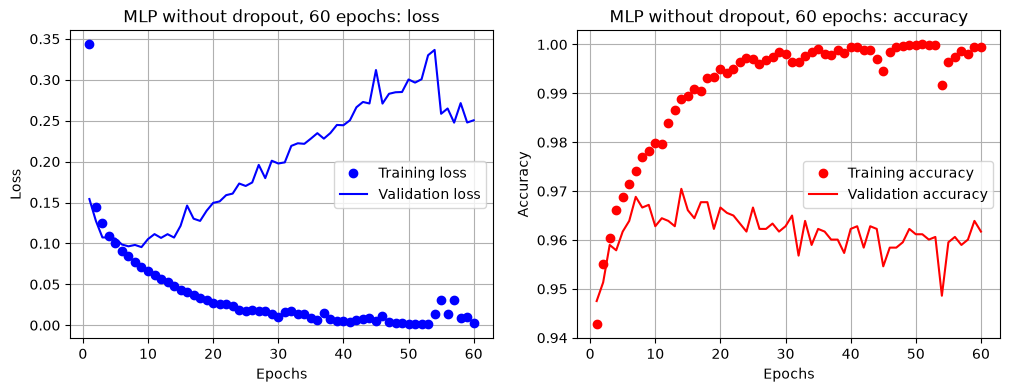

Мінімум val_loss на епосі: 9 0.0955
val_loss на останній епосі: 0.2505
train_loss на останній епосі: 0.0026
train_acc на останній епосі: 0.9995
val_acc на останній епосі: 0.9617


In [83]:
plot_curves(train_loss_history, val_loss_history,
            train_acc_history, val_acc_history, "MLP without dropout, 60 epochs")

print("Мінімум val_loss на епосі:", int(np.argmin(val_loss_history)) + 1, round(min(val_loss_history), 4))
print("val_loss на останній епосі:", round(val_loss_history[-1], 4))
print("train_loss на останній епосі:", round(train_loss_history[-1], 4))
print("train_acc на останній епосі:", round(train_acc_history[-1], 4))
print("val_acc на останній епосі:", round(val_acc_history[-1], 4))

##### Аналіз learning curves: чи спостерігається перенавчання?

Так, перенавчання є. Тренувальна втрата монотонно спадає майже до нуля, тобто мережа запам'ятовує дані, а валідаційна досягає мінімуму приблизно на 10-й епосі й далі зростає. Точка, де валідаційна крива розвертається вгору, і є моментом початку перенавчання.

Графік accuracy показує іншу картину: `train_acc` зростає майже до 1.0, а `val_acc` виходить на плато й майже не падає. Тобто мережа дає ті самі відповіді, але стає в них надмірно впевненою, у тому числі в помилкових. Втрата це штрафує, а accuracy ні, тому перенавчання визначають за втратою.

Висновок: 60 епох завеликі, і далі застосовуються dropout та early stopping.

In [84]:
grid = [
    (32, 16, 0.0, 1e-3),
    (64, 32, 0.0, 1e-3),
    (128, 64, 0.0, 1e-3),
    (64, 32, 0.3, 1e-3),
    (128, 64, 0.3, 1e-3),
    (64, 32, 0.0, 1e-2),
    (64, 32, 0.0, 1e-4)
]

results = []

for hidden1, hidden2, p_drop, lr in grid:
    torch.manual_seed(10)
    grid_model = PhishingMLP(hidden1, hidden2, p_drop).to(device)
    grid_criterion = nn.CrossEntropyLoss()
    grid_optimizer = torch.optim.Adam(grid_model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_epoch = 0
    val_accs = []

    for epoch in range(30):
        train_one_epoch(grid_model, train_loader, grid_optimizer, grid_criterion, device)
        val_loss = evaluate_one_epoch(grid_model, val_loader, grid_criterion, device)
        val_accs.append(evaluate_accuracy(grid_model, val_loader, device))

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            torch.save(grid_model.state_dict(), 'mlp_grid_best.pth')

    grid_model.load_state_dict(torch.load('mlp_grid_best.pth'))
    test_acc = evaluate_accuracy(grid_model, test_loader, device)

    results.append([hidden1, hidden2, p_drop, lr, best_val_loss, best_epoch, max(val_accs), test_acc])
    print(f"h1={hidden1} h2={hidden2} drop={p_drop} lr={lr} | best_val_loss={best_val_loss:.4f} @ep{best_epoch} | test_acc={test_acc:.4f}")

results_df = pd.DataFrame(results, columns=['hidden1', 'hidden2', 'dropout', 'lr',
                                            'best_val_loss', 'best_epoch', 'best_val_acc', 'test_acc'])
results_df = results_df.sort_values('best_val_loss')
print(results_df)

h1=32 h2=16 drop=0.0 lr=0.001 | best_val_loss=0.1004 @ep12 | test_acc=0.9536
h1=64 h2=32 drop=0.0 lr=0.001 | best_val_loss=0.0918 @ep9 | test_acc=0.9571
h1=128 h2=64 drop=0.0 lr=0.001 | best_val_loss=0.0952 @ep5 | test_acc=0.9541
h1=64 h2=32 drop=0.3 lr=0.001 | best_val_loss=0.0967 @ep13 | test_acc=0.9584
h1=128 h2=64 drop=0.3 lr=0.001 | best_val_loss=0.0911 @ep11 | test_acc=0.9589
h1=64 h2=32 drop=0.0 lr=0.01 | best_val_loss=0.1044 @ep5 | test_acc=0.9510
h1=64 h2=32 drop=0.0 lr=0.0001 | best_val_loss=0.1008 @ep30 | test_acc=0.9519
   hidden1  hidden2  dropout      lr  best_val_loss  best_epoch  best_val_acc  \
4      128       64      0.3  0.0010       0.091054          11      0.971022   
1       64       32      0.0  0.0010       0.091785           9      0.969929   
2      128       64      0.0  0.0010       0.095249           5      0.972116   
3       64       32      0.3  0.0010       0.096706          13      0.971022   
0       32       16      0.0  0.0010       0.100367      

##### Підбір гіперпараметрів

`GridSearchCV` тут незручний, бо модель написана в PyTorch, а крос-валідація множила б час навчання на 5. Тому перебір зроблено звичайним циклом: кожна конфігурація вчиться 30 епох, і порівнюється найменша втрата на валідації. Перебираються розмір прихованих шарів, dropout та швидкість навчання.

Усередині циклу працює early stopping: щойно валідаційна втрата стає найменшою, ваги зберігаються через `torch.save`, а після 30 епох модель їх завантажує.

Конфігурації з lr=1e-3 дають близькі val_loss, тобто задача мало чутлива до розміру шарів; з dropout мінімум настає пізніше; а якщо мінімум припав на останню епоху, значить епох не вистачило.

Вибір робиться за валідаційною втратою, а не за `test_acc`, інакше тест перестав би бути незалежним. Дві найкращі конфігурації відрізняються на 0.0007 втрати, тобто практично не відрізняються, тому з них узято простішу — (64, 32) без dropout.

In [85]:
torch.manual_seed(10)
final_model = PhishingMLP(64, 32, 0.0).to(device)
final_criterion = nn.CrossEntropyLoss()
final_optimizer = torch.optim.Adam(final_model.parameters(), lr=1e-3)

final_train_loss = []
final_val_loss = []
final_train_acc = []
final_val_acc = []

best_val_loss = float('inf')
best_epoch = 0

for epoch in range(30):
    tl = train_one_epoch(final_model, train_loader, final_optimizer, final_criterion, device)
    vl = evaluate_one_epoch(final_model, val_loader, final_criterion, device)
    ta = evaluate_accuracy(final_model, train_loader, device)
    va = evaluate_accuracy(final_model, val_loader, device)

    final_train_loss.append(tl)
    final_val_loss.append(vl)
    final_train_acc.append(ta)
    final_val_acc.append(va)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(final_model.state_dict(), 'mlp_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f} | train_acc={ta:.4f} | val_acc={va:.4f}")

print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
final_model.load_state_dict(torch.load('mlp_best.pth'))

[01] train_loss=0.3279 | val_loss=0.1500 | train_acc=0.9422 | val_acc=0.9481
[02] train_loss=0.1434 | val_loss=0.1176 | train_acc=0.9572 | val_acc=0.9579
[03] train_loss=0.1243 | val_loss=0.1093 | train_acc=0.9605 | val_acc=0.9584
[04] train_loss=0.1128 | val_loss=0.1012 | train_acc=0.9661 | val_acc=0.9628
[05] train_loss=0.1039 | val_loss=0.1064 | train_acc=0.9665 | val_acc=0.9563
[06] train_loss=0.0951 | val_loss=0.0995 | train_acc=0.9721 | val_acc=0.9716
[07] train_loss=0.0881 | val_loss=0.0977 | train_acc=0.9735 | val_acc=0.9639
[08] train_loss=0.0797 | val_loss=0.0991 | train_acc=0.9755 | val_acc=0.9656
[09] train_loss=0.0744 | val_loss=0.0980 | train_acc=0.9792 | val_acc=0.9672
[10] train_loss=0.0676 | val_loss=0.0963 | train_acc=0.9813 | val_acc=0.9672
[11] train_loss=0.0644 | val_loss=0.0954 | train_acc=0.9815 | val_acc=0.9677
[12] train_loss=0.0612 | val_loss=0.1015 | train_acc=0.9840 | val_acc=0.9639
[13] train_loss=0.0551 | val_loss=0.1181 | train_acc=0.9856 | val_acc=0.9677

<All keys matched successfully>

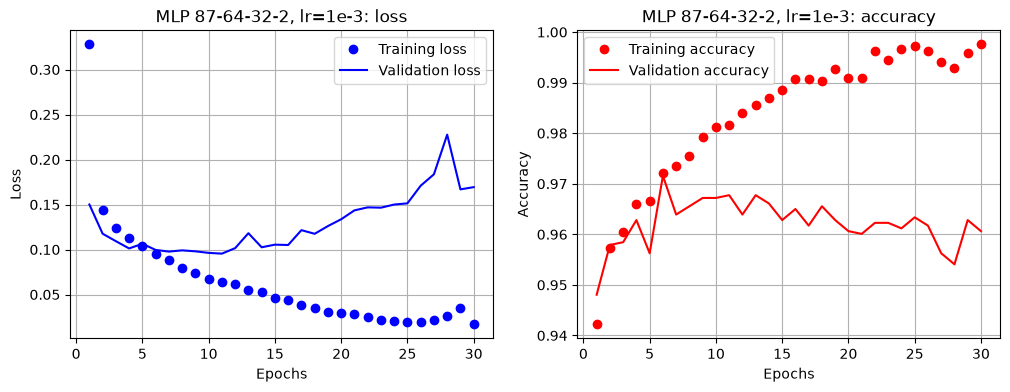

train_acc найкращої моделі: 0.9815
val_acc найкращої моделі: 0.9677


In [86]:
plot_curves(final_train_loss, final_val_loss,
            final_train_acc, final_val_acc, "MLP 87-64-32-2, lr=1e-3")

print("train_acc найкращої моделі:", round(evaluate_accuracy(final_model, train_loader, device), 4))
print("val_acc найкращої моделі:", round(evaluate_accuracy(final_model, val_loader, device), 4))

MLP test accuracy: 0.9563
[[1096   47]
 [  53 1090]]
              precision    recall  f1-score   support

           0     0.9539    0.9589    0.9564      1143
           1     0.9587    0.9536    0.9561      1143

    accuracy                         0.9563      2286
   macro avg     0.9563    0.9563    0.9563      2286
weighted avg     0.9563    0.9563    0.9563      2286



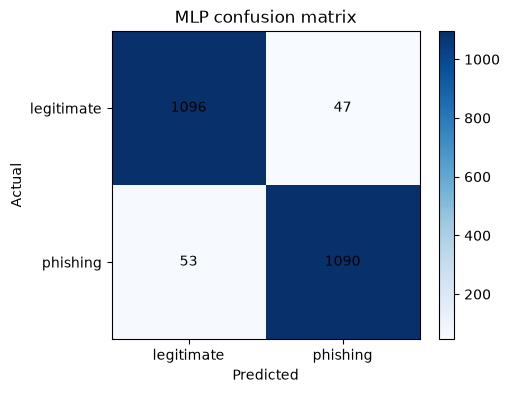

In [87]:
mlp_true, mlp_pred = predict_all(final_model, test_loader, device)

mlp_acc = accuracy_score(mlp_true, mlp_pred)
print("MLP test accuracy:", round(mlp_acc, 4))
print(confusion_matrix(mlp_true, mlp_pred))
print(classification_report(mlp_true, mlp_pred, digits=4))

cm = confusion_matrix(mlp_true, mlp_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['legitimate', 'phishing'])
plt.yticks([0, 1], ['legitimate', 'phishing'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MLP confusion matrix')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

##### Якість фінальної моделі на тесті

Перший рядок це легітимні сторінки (правильні відповіді та хибні тривоги), другий фішингові (пропущений фішинг та правильно знайдений).

Помилки виходять приблизно симетричними, бо класи збалансовані, а функція втрат не має ваг класів. Для практики це не ідеально: пропущений фішинг гірший за хибну тривогу. Якби треба було зменшити саме пропуски, можна було б задати `nn.CrossEntropyLoss(weight=...)` або знизити поріг класифікації.

In [88]:
seed_accs = []

for seed in [10, 20, 30, 40, 50]:
    torch.manual_seed(seed)
    seed_model = PhishingMLP(64, 32, 0.0).to(device)
    seed_criterion = nn.CrossEntropyLoss()
    seed_optimizer = torch.optim.Adam(seed_model.parameters(), lr=1e-3)

    seed_best = float('inf')
    for epoch in range(30):
        train_one_epoch(seed_model, train_loader, seed_optimizer, seed_criterion, device)
        vl = evaluate_one_epoch(seed_model, val_loader, seed_criterion, device)
        if vl < seed_best:
            seed_best = vl
            torch.save(seed_model.state_dict(), 'mlp_seed_best.pth')

    seed_model.load_state_dict(torch.load('mlp_seed_best.pth'))
    acc = evaluate_accuracy(seed_model, test_loader, device)
    seed_accs.append(acc)
    print(f"seed={seed}: val_loss={seed_best:.4f} test_acc={acc:.4f}")

print("test_acc: mean %.4f std %.4f min %.4f max %.4f" % (
    np.mean(seed_accs), np.std(seed_accs), min(seed_accs), max(seed_accs)))

seed=10: val_loss=0.0905 test_acc=0.9571
seed=20: val_loss=0.0958 test_acc=0.9584
seed=30: val_loss=0.0960 test_acc=0.9558
seed=40: val_loss=0.1033 test_acc=0.9580
seed=50: val_loss=0.0979 test_acc=0.9598
test_acc: mean 0.9578 std 0.0013 min 0.9558 max 0.9598


##### Стабільність результату

Нейронна мережа має багато джерел випадковості: початкові ваги, порядок батчів, маска dropout. Тому один запуск нічого не доводить, і та сама конфігурація навчається з кількох сідів (єдине місце, де сід змінюється навмисно). Розкид між запусками дає одиницю вимірювання: різниці, менші за нього, не варто брати до уваги.

                        Model  Accuracy  Errors                       Type
0        Random Forest (lab1)    0.9670      76   ансамбль дерев (bagging)
1  SVM C=10 gamma=0.01 (lab1)    0.9600      92              ядровий метод
2       MLP 87-64-32-2 (lab3)    0.9563     100            нейронна мережа
3              kNN k=5 (lab1)    0.9390     139                  метричний
4             AdaBoost (lab1)    0.9390     140  ансамбль дерев (boosting)
5        Decision Tree (lab1)    0.9300     161                одне дерево


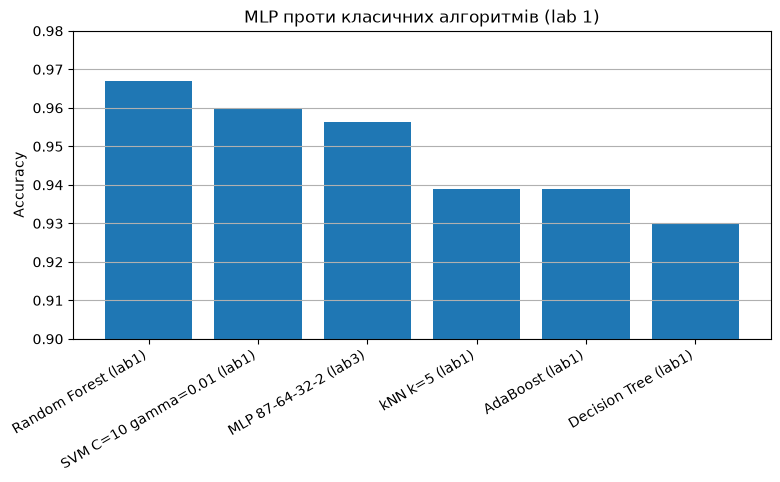

In [89]:
comparison = pd.DataFrame({
    'Model': ['Random Forest (lab1)', 'SVM C=10 gamma=0.01 (lab1)',
              'MLP 87-64-32-2 (lab3)', 'kNN k=5 (lab1)',
              'AdaBoost (lab1)', 'Decision Tree (lab1)'],
    'Accuracy': [0.967, 0.960, round(mlp_acc, 4), 0.939, 0.939, 0.930],
    'Errors': [76, 92, 2286 - int(round(mlp_acc * 2286)), 139, 140, 161],
    'Type': ['ансамбль дерев (bagging)', 'ядровий метод', 'нейронна мережа',
             'метричний', 'ансамбль дерев (boosting)', 'одне дерево']
})
comparison = comparison.sort_values('Accuracy', ascending=False)
print(comparison)

plt.figure(figsize=(9, 4))
plt.bar(comparison['Model'], comparison['Accuracy'])
plt.xticks(rotation=30, ha='right')
plt.ylim(0.90, 0.98)
plt.ylabel('Accuracy')
plt.title('MLP проти класичних алгоритмів (lab 1)')
plt.grid(axis='y')
plt.show()

##### Порівняння з класичними алгоритмами з лабораторної роботи 1

| Модель | Accuracy | FP / FN |
|---|---|---|
| Random Forest | 0.967 | 33 / 43 |
| SVM, C=10, gamma=0.01 | 0.960 | 44 / 48 |
| kNN, k=5 | 0.939 | 49 / 90 |
| AdaBoost | 0.939 | 54 / 86 |
| Decision Tree | 0.930 | 54 / 107 |

1. Нейронна мережа не перемогла: вона приблизно на рівні SVM і гірша за Random Forest, хоча й краща за kNN, AdaBoost і одне дерево.
2. Це закономірно. Сила нейромережі в тому, що вона сама будує ознаки з сирих даних, а тут вони вже побудовані людиною. До того ж залежності порогові («якщо page_rank <= 1, то скоріше фішинг»): дерево знаходить такий поріг одним розбиттям, а MLP мусить наближати ступінчасту функцію сумою ReLU-зламів.
3. Перевага нейромереж має проявитися там, де ознаки сирі: пікселі та слова.

# Частина 2. Згорткові нейронні мережі (CNN) для класифікації зображень

##### Опис датасету та постановка задачі

Датасет містить 2 527 фотографій сміття, розкладених по теках за матеріалом. Задача: за фотографією визначити матеріал, тобто класифікація на 6 класів.

| Клас | Переклад | Кількість |
|---|---|---|
| cardboard | картон | 403 |
| glass | скло | 501 |
| metal | метал | 410 |
| paper | папір | 594 |
| plastic | пластик | 482 |
| trash | інше сміття | 137 |

Зображення 512x384, по одному об'єкту на світлому тлі. Класи незбалансовані, тому поряд з accuracy дивимося на macro-F1.

In [90]:
from torchvision import datasets, transforms, utils
from torchvision import models

In [91]:
data_dir = 'garbage/Garbage classification/Garbage classification'

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

tf_small = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

tf_imagenet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

##### Transforms: два різні препроцесинги

`transforms.Compose` це конвеєр перетворень для кожного зображення при завантаженні. Конвеєрів два, бо дві моделі очікують різний вхід.

Для власної CNN: `Resize((64, 64))`, бо мережа вимагає однакового розміру входу, а складність згортки пропорційна площі (512x384 був би у 48 разів дорожчим). `ToTensor()` дає тензор [3, 64, 64] і масштабує пікселі у 0-1.

Для pretrained-моделі: `Resize((224, 224))`, бо MobileNet тренувалася на ImageNet саме на такому розмірі, та `Normalize` зі значеннями ImageNet. Модель очікує дані в тому самому розподілі, в якому вчилася, інакше результат буде значно гіршим без жодного повідомлення про помилку.

In [92]:
full_small = datasets.ImageFolder(data_dir, transform=tf_small)
full_imagenet = datasets.ImageFolder(data_dir, transform=tf_imagenet)

classes = full_small.classes
num_classes = len(classes)
targets = np.array(full_small.targets)

print("Класи:", classes)
print("Усього зображень:", len(full_small))
for i in range(num_classes):
    print(classes[i], int((targets == i).sum()))

x0, y0 = full_small[0]
print("Приклад тензора:", x0.shape, "dtype:", x0.dtype, "min/max:", float(x0.min()), float(x0.max()))

Класи: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Усього зображень: 2527
cardboard 403
glass 501
metal 410
paper 594
plastic 482
trash 137
Приклад тензора: torch.Size([3, 64, 64]) dtype: torch.float32 min/max: 0.07450980693101883 0.9607843160629272


##### ImageFolder

`datasets.ImageFolder` зручний для датасетів, розкладених по теках: назва теки стає класом, і файл з мітками не потрібен. Класи нумеруються за алфавітом.

Створюються два об'єкти на тих самих файлах, але з різними `transform`, бо власна CNN працює з 64x64, а MobileNet з 224x224. Самі файли не дублюються: `ImageFolder` зберігає лише шляхи.

In [93]:
idx_all = np.arange(len(full_small))

idx_trainval, idx_test = train_test_split(
    idx_all, test_size=0.15, random_state=10, stratify=targets)

idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.1765, random_state=10, stratify=targets[idx_trainval])

print("train/val/test:", len(idx_train), len(idx_val), len(idx_test))

for i in range(num_classes):
    print(classes[i],
          int((targets[idx_train] == i).sum()),
          int((targets[idx_val] == i).sum()),
          int((targets[idx_test] == i).sum()))

train/val/test: 1768 379 380
cardboard 282 60 61
glass 351 75 75
metal 286 62 62
paper 416 89 89
plastic 338 72 72
trash 95 21 21


In [94]:
train_small = Subset(full_small, idx_train)
val_small = Subset(full_small, idx_val)
test_small = Subset(full_small, idx_test)

train_imgnet = Subset(full_imagenet, idx_train)
val_imgnet = Subset(full_imagenet, idx_val)
test_imgnet = Subset(full_imagenet, idx_test)

train_loader_s = DataLoader(train_small, batch_size=32, shuffle=True)
val_loader_s = DataLoader(val_small, batch_size=32, shuffle=False)
test_loader_s = DataLoader(test_small, batch_size=32, shuffle=False)

train_loader_b = DataLoader(train_imgnet, batch_size=32, shuffle=True)
val_loader_b = DataLoader(val_imgnet, batch_size=32, shuffle=False)
test_loader_b = DataLoader(test_imgnet, batch_size=32, shuffle=False)

for xb, yb in train_loader_s:
    print(xb.shape, yb.shape)
    break

torch.Size([32, 3, 64, 64]) torch.Size([32])


##### Розбиття вибірки

Розбиття робиться один раз по індексах, а не окремо для кожного `ImageFolder`: обидві моделі мусять навчатися й тестуватися на тих самих зображеннях.

Пропорція 70 / 15 / 15: спочатку 15% на тест, потім від решти ще 15% від початкового обсягу на валідацію (звідси `test_size=0.1765`). Разом 1 768 / 379 / 380 зображень.

`stratify=targets` зберігає пропорції класів, що особливо важливо для малого класу trash: на нього припадає близько 20 зображень у тесті, тому метрики для нього шумні.

`batch_size=32`, а не 128, бо даних лише 1 768: при батчі 128 епоха складалася б з 14 кроків оптимізатора.

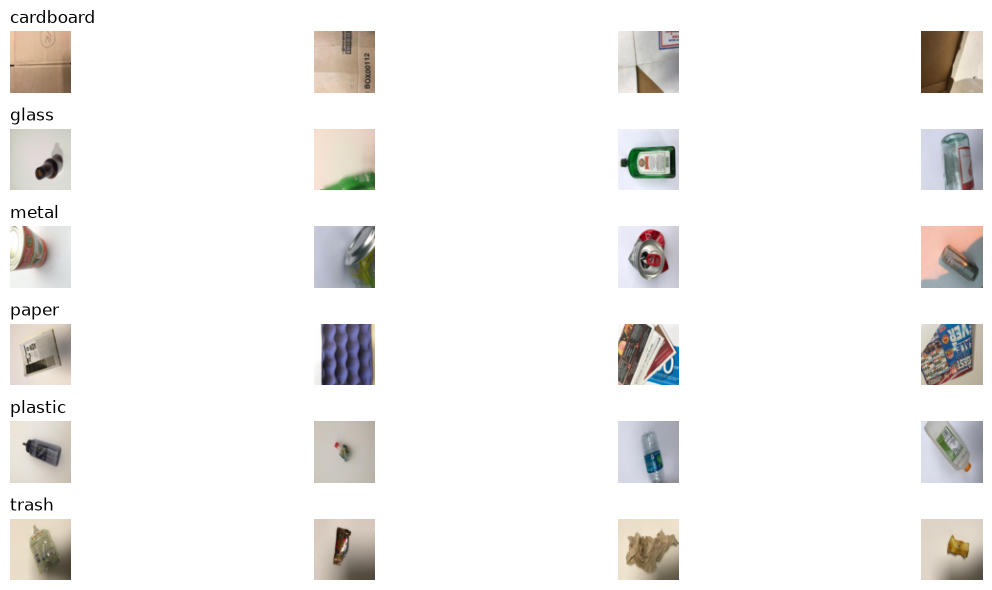

In [95]:
plt.figure(figsize=(14, 6))

for i in range(num_classes):
    class_indices = np.where(targets == i)[0][:4]
    for j in range(4):
        img, label = full_small[class_indices[j]]
        plt.subplot(num_classes, 4, i * 4 + j + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.axis('off')
        if j == 0:
            plt.title(classes[i], loc='left')

plt.tight_layout()
plt.show()

Мітки: ['trash', 'cardboard', 'plastic', 'trash', 'plastic', 'plastic', 'paper', 'paper']


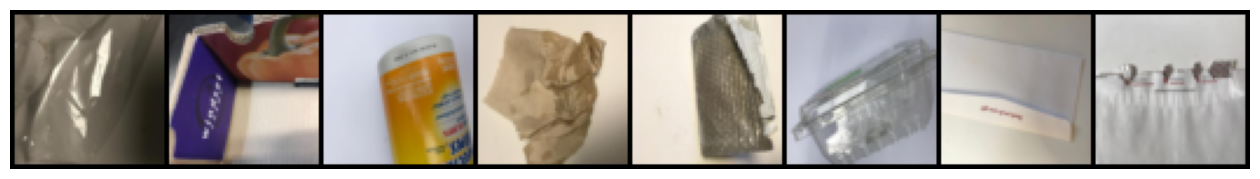

In [96]:
def show_batch(dataset, n=8):
    idx = torch.randperm(len(dataset))[:n]
    imgs = [dataset[i][0] for i in idx]
    labels = [dataset[i][1] for i in idx]
    grid = utils.make_grid(imgs, nrow=n, padding=2)
    plt.figure(figsize=(2 * n, 2.5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    print("Мітки:", [classes[l] for l in labels])
    plt.show()


show_batch(full_small, n=8)

`img.permute(1, 2, 0)` потрібен тому що PyTorch зберігає зображення як [канали, висота, ширина], а matplotlib очікує [висота, ширина, канали].

Що видно й що з цього можна передбачити: умови зйомки однакові (один об'єкт на світлому тлі), тому навчена тут модель не обов'язково працюватиме на реальній лінії; glass, metal і plastic схожі, бо це бутлі схожої форми, і відрізняються текстурою та відблисками, тому основні помилки очікувались тут; trash це збірний клас без спільної ознаки, і він найменший, тому має бути найгіршим за метриками.

Другий графік показує випадковий батч уже після всіх `transforms`.

In [97]:
class GarbageCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout(0.25)

        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.drop(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        logits = self.fc2(x)
        return logits


torch.manual_seed(10)
cnn_model = GarbageCNN(num_classes).to(device)
print(cnn_model)
print("Trainable params:", sum(p.numel() for p in cnn_model.parameters() if p.requires_grad))

GarbageCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)
Trainable params: 2192646


##### Архітектура власної CNN

Три згорткові блоки й два повнозв'язані шари:

| Крок | Форма |
|---|---|
| вхід | [B, 3, 64, 64] |
| conv1 + pool | [B, 32, 32, 32] |
| conv2 + pool | [B, 64, 16, 16] |
| conv3 + pool | [B, 128, 8, 8] |
| flatten | [B, 8192] |
| fc1 / fc2 | [B, 256] / [B, 6] |

__Чому згортка, а не повнозв'язаний шар.__ Можна було б розгорнути 12 288 пікселів і подати в MLP, але тоді перший шар мав би 3.1 мільйона параметрів (у `conv1` їх 896), flatten знищив би інформацію про те, які пікселі сусідні, і мережа мусила б окремо вчити блиск металу в кожній позиції. Згортка вчить один фільтр і застосовує його в усіх позиціях одразу.

`padding=1` додає рамку з нулів, щоб розмір не зменшувався, а `nn.MaxPool2d(2, 2)` залишає максимум з кожного квадрата 2x2: менше обчислень і нечутливість до положення ознаки. Блоки стоять послідовно, щоб будувати ознаки поступово: краї, потім текстури, потім фрагменти об'єктів.

`nn.Dropout(0.25)` протидіє перенавчанню, яке тут неминуче: 2.19 мільйона параметрів на 1 768 зображень, причому 96% з них припадає на `fc1`.

In [98]:
criterion_img = nn.CrossEntropyLoss()
optimizer_cnn = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)

n_epochs = 30

cnn_train_loss = []
cnn_val_loss = []
cnn_train_acc = []
cnn_val_acc = []

best_val_loss = float('inf')
best_epoch = 0
start_time = time.time()

for epoch in range(n_epochs):
    tl = train_one_epoch(cnn_model, train_loader_s, optimizer_cnn, criterion_img, device)
    vl = evaluate_one_epoch(cnn_model, val_loader_s, criterion_img, device)
    ta = evaluate_accuracy(cnn_model, train_loader_s, device)
    va = evaluate_accuracy(cnn_model, val_loader_s, device)

    cnn_train_loss.append(tl)
    cnn_val_loss.append(vl)
    cnn_train_acc.append(ta)
    cnn_val_acc.append(va)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(cnn_model.state_dict(), 'cnn_scratch_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f} | train_acc={ta:.4f} | val_acc={va:.4f}")

cnn_time = time.time() - start_time
print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
print("Час навчання, с:", round(cnn_time, 1))
cnn_model.load_state_dict(torch.load('cnn_scratch_best.pth'))

[01] train_loss=1.7054 | val_loss=1.2054 | train_acc=0.5594 | val_acc=0.5251
[02] train_loss=1.0988 | val_loss=1.0559 | train_acc=0.6669 | val_acc=0.6174
[03] train_loss=1.0011 | val_loss=2.0884 | train_acc=0.4700 | val_acc=0.4459
[04] train_loss=0.8895 | val_loss=1.0946 | train_acc=0.7053 | val_acc=0.5937
[05] train_loss=0.8383 | val_loss=1.0984 | train_acc=0.6589 | val_acc=0.5620
[06] train_loss=0.8033 | val_loss=1.0240 | train_acc=0.7800 | val_acc=0.6544
[07] train_loss=0.7264 | val_loss=1.2558 | train_acc=0.7325 | val_acc=0.6201
[08] train_loss=0.6879 | val_loss=0.9492 | train_acc=0.8416 | val_acc=0.6491
[09] train_loss=0.6086 | val_loss=1.2759 | train_acc=0.6702 | val_acc=0.5831
[10] train_loss=0.6182 | val_loss=1.2664 | train_acc=0.7008 | val_acc=0.5805
[11] train_loss=0.5351 | val_loss=1.0280 | train_acc=0.8541 | val_acc=0.6807
[12] train_loss=0.5056 | val_loss=3.7460 | train_acc=0.4729 | val_acc=0.3879
[13] train_loss=0.4662 | val_loss=1.6830 | train_acc=0.6900 | val_acc=0.5383

<All keys matched successfully>

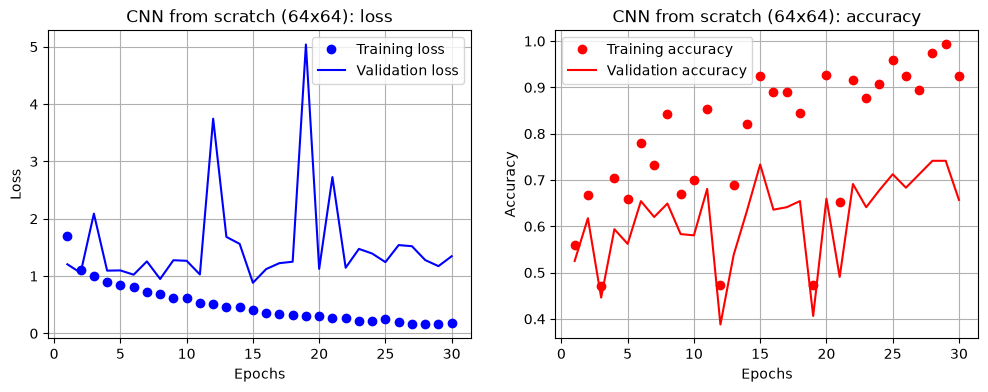

In [99]:
plot_curves(cnn_train_loss, cnn_val_loss, cnn_train_acc, cnn_val_acc,
            "CNN from scratch (64x64)")

In [100]:
cnn_true, cnn_pred = predict_all(cnn_model, test_loader_s, device)

cnn_acc = accuracy_score(cnn_true, cnn_pred)
cnn_f1 = f1_score(cnn_true, cnn_pred, average='macro')

print("CNN from scratch: test accuracy", round(cnn_acc, 4), "| macro F1", round(cnn_f1, 4))
print(confusion_matrix(cnn_true, cnn_pred))
print(classification_report(cnn_true, cnn_pred, target_names=classes, digits=4))

CNN from scratch: test accuracy 0.7368 | macro F1 0.7208
[[51  4  0  3  3  0]
 [ 1 51  4  0 15  4]
 [ 2  9 39  1  8  3]
 [ 0  4  3 76  6  0]
 [ 2  6  4  9 50  1]
 [ 4  1  2  1  0 13]]
              precision    recall  f1-score   support

   cardboard     0.8500    0.8361    0.8430        61
       glass     0.6800    0.6800    0.6800        75
       metal     0.7500    0.6290    0.6842        62
       paper     0.8444    0.8539    0.8492        89
     plastic     0.6098    0.6944    0.6494        72
       trash     0.6190    0.6190    0.6190        21

    accuracy                         0.7368       380
   macro avg     0.7255    0.7188    0.7208       380
weighted avg     0.7405    0.7368    0.7373       380



##### Аналіз навчання CNN з нуля

Тренувальна втрата спадає рівно, а валідаційна значно гірше: вона досягає мінімуму приблизно на 10-15 епосі, далі коливається й може різко стрибати вгору. Тренувальна accuracy доходить до 0.95+, валідаційна застрягає помітно нижче. Перенавчання сильне, і це очікувано при 2.19 мільйона параметрів на 1 768 зображень.

__Чому валідаційна крива така нестабільна.__ Валідаційна вибірка маленька (379 зображень), тому 10 помилок змінюють accuracy на 2.6 п.п. BatchNorm у навчанні бере статистику батча, а при оцінюванні збережену, і поки навчання нестабільне, вони розходяться.

У `classification_report` найгіршим має бути trash, а основна плутанина між glass, metal і plastic, як і передбачено з перегляду зображень.

In [101]:
mobilenet = models.mobilenet_v2(pretrained=True)
print(mobilenet.classifier)
print("Кількість блоків у features:", len(mobilenet.features))

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)
Кількість блоків у features: 19


/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [102]:
for p in mobilenet.features.parameters():
    p.requires_grad = False

in_features = mobilenet.classifier[1].in_features
mobilenet.classifier[1] = nn.Linear(in_features, num_classes)

mobilenet = mobilenet.to(device)

total = sum(p.numel() for p in mobilenet.parameters())
trainable = sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)
print(f"total: {total:,} | trainable: {trainable:,}")

total: 2,231,558 | trainable: 7,686


##### Transfer learning: pretrained MobileNetV2

`models.mobilenet_v2(pretrained=True)` завантажує архітектуру разом з вагами, натренованими на ImageNet (1.2 мільйона зображень, 1 000 класів). Її згорткові шари вивчили універсальні ознаки (краї, текстури, відблиски), корисні майже для будь-якої задачі з фотографіями, у тому числі для розрізнення скла, металу й пластику за блиском.

`p.requires_grad = False` для всіх параметрів `features` означає, що градієнти для них не рахуються і ваги не оновлюються: згорткова частина стає фіксованим екстрактором ознак. А вихідний шар має 1 000 виходів під класи ImageNet, тому замінюється на новий `nn.Linear(1280, 6)` (`in_features` беремо з наявного шару, щоб код працював і з іншою моделью).

Результат: усього 2 231 558 параметрів, а тренувальних лише 7 686, тобто 0.34%. У власної CNN тренувалися всі 2.19 мільйона на тих самих даних. Через це transfer learning є ефективним на малих датасетах.

In [103]:
optimizer_mob = torch.optim.Adam(mobilenet.parameters(), lr=1e-3)

n_epochs = 10

mob_train_loss = []
mob_val_loss = []
mob_train_acc = []
mob_val_acc = []

best_val_loss = float('inf')
best_epoch = 0
start_time = time.time()

for epoch in range(n_epochs):
    tl = train_one_epoch(mobilenet, train_loader_b, optimizer_mob, criterion_img, device)
    vl = evaluate_one_epoch(mobilenet, val_loader_b, criterion_img, device)
    ta = evaluate_accuracy(mobilenet, train_loader_b, device)
    va = evaluate_accuracy(mobilenet, val_loader_b, device)

    mob_train_loss.append(tl)
    mob_val_loss.append(vl)
    mob_train_acc.append(ta)
    mob_val_acc.append(va)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(mobilenet.state_dict(), 'mobilenet_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f} | train_acc={ta:.4f} | val_acc={va:.4f}")

mob_time = time.time() - start_time
print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
print("Час навчання, с:", round(mob_time, 1))
mobilenet.load_state_dict(torch.load('mobilenet_best.pth'))

[01] train_loss=1.0918 | val_loss=0.8271 | train_acc=0.7834 | val_acc=0.7045
[02] train_loss=0.6676 | val_loss=0.6713 | train_acc=0.8501 | val_acc=0.7652
[03] train_loss=0.5815 | val_loss=0.6101 | train_acc=0.8660 | val_acc=0.7889
[04] train_loss=0.5159 | val_loss=0.5658 | train_acc=0.8914 | val_acc=0.8259
[05] train_loss=0.4567 | val_loss=0.5612 | train_acc=0.8886 | val_acc=0.8127
[06] train_loss=0.4397 | val_loss=0.5640 | train_acc=0.8869 | val_acc=0.8074
[07] train_loss=0.4204 | val_loss=0.5313 | train_acc=0.9169 | val_acc=0.8232
[08] train_loss=0.3938 | val_loss=0.5098 | train_acc=0.9253 | val_acc=0.8391
[09] train_loss=0.3874 | val_loss=0.5221 | train_acc=0.9180 | val_acc=0.8496
[10] train_loss=0.3660 | val_loss=0.5043 | train_acc=0.9321 | val_acc=0.8391
Найкраща епоха: 10 val_loss: 0.5043
Час навчання, с: 113.9


<All keys matched successfully>

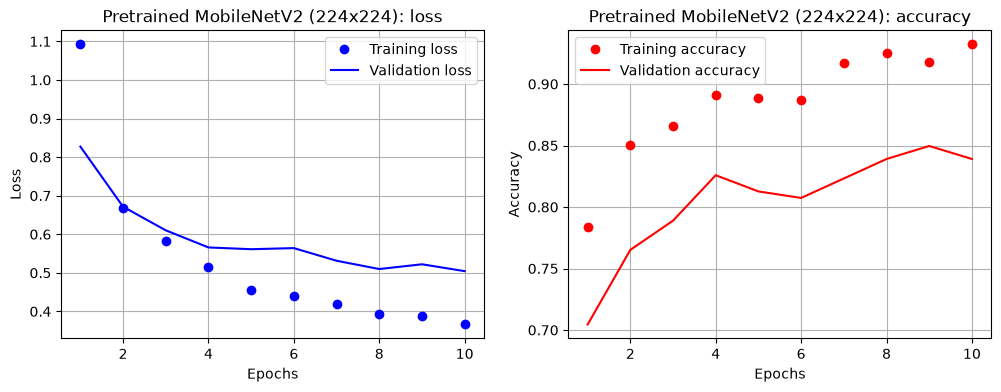

In [104]:
plot_curves(mob_train_loss, mob_val_loss, mob_train_acc, mob_val_acc,
            "Pretrained MobileNetV2 (224x224)")

In [105]:
mob_true, mob_pred = predict_all(mobilenet, test_loader_b, device)

mob_acc = accuracy_score(mob_true, mob_pred)
mob_f1 = f1_score(mob_true, mob_pred, average='macro')

print("MobileNetV2: test accuracy", round(mob_acc, 4), "| macro F1", round(mob_f1, 4))
print(confusion_matrix(mob_true, mob_pred))
print(classification_report(mob_true, mob_pred, target_names=classes, digits=4))

MobileNetV2: test accuracy 0.8316 | macro F1 0.8023
[[53  0  1  5  0  2]
 [ 0 63  5  0  7  0]
 [ 0  8 50  0  3  1]
 [ 3  0  2 83  0  1]
 [ 0  9  4  3 56  0]
 [ 1  1  2  5  1 11]]
              precision    recall  f1-score   support

   cardboard     0.9298    0.8689    0.8983        61
       glass     0.7778    0.8400    0.8077        75
       metal     0.7812    0.8065    0.7937        62
       paper     0.8646    0.9326    0.8973        89
     plastic     0.8358    0.7778    0.8058        72
       trash     0.7333    0.5238    0.6111        21

    accuracy                         0.8316       380
   macro avg     0.8204    0.7916    0.8023       380
weighted avg     0.8316    0.8316    0.8297       380



##### Якість pretrained-моделі на тесті

Pretrained-модель відчутно краща за власну CNN і за accuracy, і за macro-F1.

Per-class метрики:

1. Покращення є майже по всіх класах, і найбільше там, де власна CNN була найслабшою, тобто серед glass / metal / plastic. Розрізнити блиск металу від блиску пластику це питання тонкої текстури, і саме такі ознаки MobileNet вивчила на мільйоні зображень.
2. Єдиний клас, який не покращився, це trash: у нього F1 залишився приблизно таким самим. Він має помітно вищу precision, ніж recall, тобто модель рідко називає trash помилково, але знаходить лише половину. Причина в тому, що клас маленький і внутрішньо різнорідний, тому сумнівні об'єкти модель воліє віднести до «нормальних» класів.

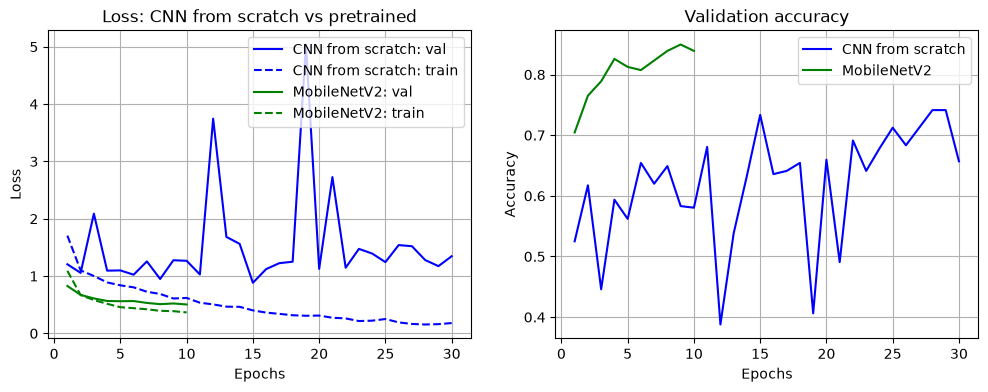

In [106]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(cnn_val_loss) + 1), cnn_val_loss, 'b', label='CNN from scratch: val')
plt.plot(range(1, len(cnn_train_loss) + 1), cnn_train_loss, 'b--', label='CNN from scratch: train')
plt.plot(range(1, len(mob_val_loss) + 1), mob_val_loss, 'g', label='MobileNetV2: val')
plt.plot(range(1, len(mob_train_loss) + 1), mob_train_loss, 'g--', label='MobileNetV2: train')
plt.title('Loss: CNN from scratch vs pretrained')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cnn_val_acc) + 1), cnn_val_acc, 'b', label='CNN from scratch')
plt.plot(range(1, len(mob_val_acc) + 1), mob_val_acc, 'g', label='MobileNetV2')
plt.title('Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

##### Аналіз learning curves pretrained-моделі та порівняння з CNN з нуля

Валідаційна втрата MobileNetV2 спадає рівно, практично без розворотів і стрибків (за всі епохи вона піднімалася лише двічі, і то на дрібні значення). Перенавчання не починається, і причина проста: навчуваних параметрів лише 7 686, тобто перенавчатися просто нічим. Мінімум припав на останню епоху, тобто модель не встигла довчитися і більша кількість епох дала б кращий результат.

На спільному графіку видно, що крива власної CNN «пиляста» і розвертається вгору, а крива MobileNet гладка й опускається значно нижче. Валідаційна accuracy MobileNet уже після першої епохи приблизно така, якої власна CNN досягає у своїй найкращій точці за всі 30 епох.

Застереження: криві мають різну довжину (30 епох проти 10), і одна епоха MobileNet приблизно втричі довша. Тому за кількістю епох pretrained-модель збігається значно швидше, а за часом повільніше.

In [107]:
idx_train_25, _ = train_test_split(
    idx_train, train_size=0.25, random_state=10, stratify=targets[idx_train])
print("Зменшена тренувальна вибірка:", len(idx_train_25))

train_loader_s25 = DataLoader(Subset(full_small, idx_train_25), batch_size=32, shuffle=True)
train_loader_b25 = DataLoader(Subset(full_imagenet, idx_train_25), batch_size=32, shuffle=True)

Зменшена тренувальна вибірка: 442


In [108]:
torch.manual_seed(10)
cnn_25 = GarbageCNN(num_classes).to(device)
optimizer_cnn25 = torch.optim.Adam(cnn_25.parameters(), lr=1e-3)

best_val_loss = float('inf')
cnn25_val_loss = []

for epoch in range(30):
    tl = train_one_epoch(cnn_25, train_loader_s25, optimizer_cnn25, criterion_img, device)
    vl = evaluate_one_epoch(cnn_25, val_loader_s, criterion_img, device)
    cnn25_val_loss.append(vl)

    if vl < best_val_loss:
        best_val_loss = vl
        torch.save(cnn_25.state_dict(), 'cnn25_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f}")

cnn_25.load_state_dict(torch.load('cnn25_best.pth'))
cnn25_acc = evaluate_accuracy(cnn_25, test_loader_s, device)
print("CNN from scratch on 25% data: test accuracy", round(cnn25_acc, 4))

[01] train_loss=2.7381 | val_loss=1.7377
[02] train_loss=1.3617 | val_loss=1.6084
[03] train_loss=1.1290 | val_loss=1.3999
[04] train_loss=0.9742 | val_loss=1.2170
[05] train_loss=0.8272 | val_loss=1.1954
[06] train_loss=0.7443 | val_loss=1.5108
[07] train_loss=0.6514 | val_loss=1.2301
[08] train_loss=0.6280 | val_loss=1.9783
[09] train_loss=0.5345 | val_loss=1.1995
[10] train_loss=0.4336 | val_loss=1.1731
[11] train_loss=0.4425 | val_loss=1.3823
[12] train_loss=0.3926 | val_loss=1.1501
[13] train_loss=0.3238 | val_loss=1.3432
[14] train_loss=0.3515 | val_loss=1.4322
[15] train_loss=0.3105 | val_loss=1.6746
[16] train_loss=0.2233 | val_loss=1.3661
[17] train_loss=0.1851 | val_loss=1.9135
[18] train_loss=0.1848 | val_loss=1.4796
[19] train_loss=0.1307 | val_loss=1.4326
[20] train_loss=0.1231 | val_loss=1.4650
[21] train_loss=0.1080 | val_loss=1.6163
[22] train_loss=0.0877 | val_loss=1.6236
[23] train_loss=0.0945 | val_loss=1.5638
[24] train_loss=0.0800 | val_loss=1.4963
[25] train_loss=

In [109]:
mobilenet_25 = models.mobilenet_v2(pretrained=True)
for p in mobilenet_25.features.parameters():
    p.requires_grad = False
mobilenet_25.classifier[1] = nn.Linear(mobilenet_25.classifier[1].in_features, num_classes)
mobilenet_25 = mobilenet_25.to(device)

optimizer_mob25 = torch.optim.Adam(mobilenet_25.parameters(), lr=1e-3)

best_val_loss = float('inf')
mob25_val_loss = []

for epoch in range(10):
    tl = train_one_epoch(mobilenet_25, train_loader_b25, optimizer_mob25, criterion_img, device)
    vl = evaluate_one_epoch(mobilenet_25, val_loader_b, criterion_img, device)
    mob25_val_loss.append(vl)

    if vl < best_val_loss:
        best_val_loss = vl
        torch.save(mobilenet_25.state_dict(), 'mob25_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f}")

mobilenet_25.load_state_dict(torch.load('mob25_best.pth'))
mob25_acc = evaluate_accuracy(mobilenet_25, test_loader_b, device)
print("MobileNetV2 on 25% data: test accuracy", round(mob25_acc, 4))

/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[01] train_loss=1.6069 | val_loss=1.2844
[02] train_loss=1.1271 | val_loss=1.0653
[03] train_loss=0.8673 | val_loss=0.9166
[04] train_loss=0.7224 | val_loss=0.8426
[05] train_loss=0.6330 | val_loss=0.8026
[06] train_loss=0.5523 | val_loss=0.7855
[07] train_loss=0.5122 | val_loss=0.7451
[08] train_loss=0.4773 | val_loss=0.7310
[09] train_loss=0.4505 | val_loss=0.7121
[10] train_loss=0.4223 | val_loss=0.7052
MobileNetV2 on 25% data: test accuracy 0.7816


                   Модель  Тренувальних зображень  Test accuracy
0        CNN from scratch                     442         0.6474
1        CNN from scratch                    1768         0.7368
2  MobileNetV2 pretrained                     442         0.7816
3  MobileNetV2 pretrained                    1768         0.8316


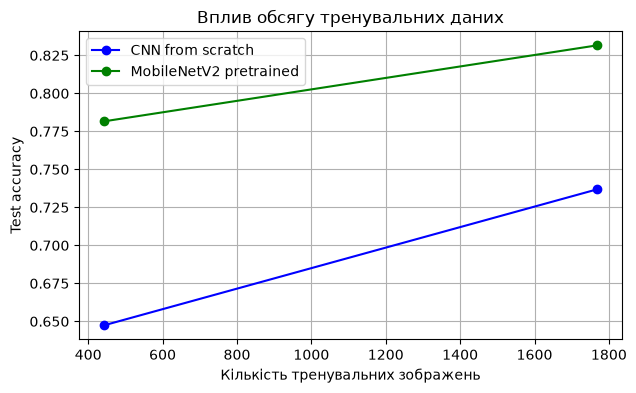

In [110]:
size_results = pd.DataFrame({
    'Модель': ['CNN from scratch', 'CNN from scratch', 'MobileNetV2 pretrained', 'MobileNetV2 pretrained'],
    'Тренувальних зображень': [len(idx_train_25), len(idx_train), len(idx_train_25), len(idx_train)],
    'Test accuracy': [round(cnn25_acc, 4), round(cnn_acc, 4), round(mob25_acc, 4), round(mob_acc, 4)]
})
print(size_results)

plt.figure(figsize=(7, 4))
plt.plot([len(idx_train_25), len(idx_train)], [cnn25_acc, cnn_acc], 'bo-', label='CNN from scratch')
plt.plot([len(idx_train_25), len(idx_train)], [mob25_acc, mob_acc], 'go-', label='MobileNetV2 pretrained')
plt.xlabel('Кількість тренувальних зображень')
plt.ylabel('Test accuracy')
plt.title('Вплив обсягу тренувальних даних')
plt.legend()
plt.grid()
plt.show()

##### Вплив обсягу тренувальних даних та висновки частини 2

Обидві моделі навчено ще раз на чверті тренувальної вибірки (442 зображення замість 1 768), при тих самих валідаційній і тестовій вибірках. Дивитися треба на нахил ліній, а не на їхню висоту.

Лінія власної CNN помітно крутіша: вона вчить усе з нуля, тому кожне зображення для неї цінне, а пологий нахил у pretrained-моделі означає, що вона вже знає більшість потрібного. Головний результат: pretrained-модель на 442 зображеннях виходить кращою, ніж власна CNN на всіх 1 768, тобто transfer learning приблизно еквівалентний збільшенню датасету в кілька разів.

__Висновки частини 2.__

1. Якість: pretrained-модель краща і за accuracy, і за macro-F1, причому майже по всіх класах.
2. Збіжність: за кількістю епох pretrained-модель швидша, за часом повільніша.
3. Learning curves: у власної CNN валідаційна втрата нестабільна й розвертається вгору, у pretrained спадає рівно й до кінця.
4. Обсяг даних: власна CNN втрачає помітно більше при скороченні даних.
5. Загалом: на 2 527 зображень навчати мережу з нуля неефективно. Наступним кроком була б аугментація даних, але тут вона не застосована, щоб обидві моделі отримали однакові дані.

# Частина 3. Нейронні мережі для класифікації текстів

##### Постановка задачі

Той самий текстовий датасет і та сама задача, що в частині 3 лабораторної роботи 2: за тегами, які користувачі поставили фільму, визначити його жанр. Там вона розв'язувалася через TF-IDF та Naive Bayes і дала accuracy 0.77 та macro-F1 0.66.

Порівнюються два підходи: а) Embedding з випадковими вагами, навчений з нуля, та б) Embedding, ініціалізований готовими векторами GloVe. Передобробка тексту повторює лабу 2.

In [111]:
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [112]:
tags = pd.read_csv('../lab2/ml-latest-small/tags.csv')
movies = pd.read_csv('../lab2/ml-latest-small/movies.csv')

print(tags.shape, movies.shape)
print(tags.head())

docs = tags.groupby('movieId')['tag'].agg(lambda s: ' '.join(str(x) for x in s)).reset_index()
data = movies.merge(docs, on='movieId')
print(data.shape)
print(data[['title', 'genres', 'tag']].head())

(3683, 4) (9742, 3)
   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200
(1572, 4)
                                title  \
0                    Toy Story (1995)   
1                      Jumanji (1995)   
2             Grumpier Old Men (1995)   
3  Father of the Bride Part II (1995)   
4                      Sabrina (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                                       Comedy   
4                               Comedy|Romance   

                                            tag  
0                               pixar pixar fun  
1  fantasy magic board game Robin 

##### Формування текстів

`groupby('movieId')['tag'].agg(' '.join)` це головний рядок: у `tags.csv` кожен рядок це один тег від одного користувача, тому щоб отримати по одному документу на фільм, усі теги склеюються в один рядок. Теги є лише в 1 572 фільмів із 9 742.

Звернути увагу: склеєний «текст» виглядає як «pixar pixar fun», тобто це не речення, і порядок слів у ньому не є змістовним. Це знадобиться у висновках.

In [113]:
chosen = ['Comedy', 'Drama', 'Horror']


def get_label(genres):
    genre_list = genres.split('|')
    found = []
    for g in chosen:
        if g in genre_list:
            found.append(g)
    if len(found) == 1:
        return found[0]
    return None


data['label'] = data['genres'].apply(get_label)
data = data.dropna(subset=['label'])
print(data['label'].value_counts())

label
Drama     682
Comedy    332
Horror     52
Name: count, dtype: int64


In [114]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub('[^a-z ]', ' ', text)
    words = text.split()
    result = []
    for word in words:
        if word not in ENGLISH_STOP_WORDS and len(word) > 2:
            result.append(word)
    return ' '.join(result)


data['clean_text'] = data['tag'].apply(clean_text)
data = data[data['clean_text'] != '']
print(data.shape)
print(data[['tag', 'clean_text', 'label']].head())

(1056, 6)
                  tag          clean_text   label
0     pixar pixar fun     pixar pixar fun  Comedy
2           moldy old           moldy old  Comedy
3    pregnancy remake    pregnancy remake  Comedy
4              remake              remake  Comedy
6  politics president  politics president   Drama


##### Вибір класів та очищення тексту

Фільм зазвичай має кілька жанрів, а нам потрібна одна мітка, тому залишаємо лише фільми з рівно одним із трьох обраних жанрів: з 1 572 залишається 1 066, а після очищення 1 056.

Класи дуже незбалансовані (Drama 682, Comedy 332, Horror 52), тому accuracy сама по собі нічого не доводить і поряд потрібен macro-F1.

`clean_text` робить те саме, що в лабі 2: нижній регістр, видалення всього, крім латинських літер, і видалення стоп-слів. Побічний ефект: після цього наші слова виглядають так само, як у файлі GloVe.

In [115]:
label_names = ['Comedy', 'Drama', 'Horror']
label_to_id = {}
for i in range(len(label_names)):
    label_to_id[label_names[i]] = i

data['y'] = data['label'].map(label_to_id)

texts = data['clean_text'].tolist()
labels = data['y'].tolist()
print(len(texts), len(labels))
print(texts[0], '->', labels[0])

1056 1056
pixar pixar fun -> 0


In [116]:
train_texts, test_texts, train_labels, test_labels = train_test_split(
    texts, labels, test_size=0.30, random_state=10, stratify=labels)

train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_texts, train_labels, test_size=0.20, random_state=10, stratify=train_labels)

print(len(train_texts), len(val_texts), len(test_texts))
print('частка Drama в тесті:', round(np.mean(np.array(test_labels) == 1), 4))

591 148 317
частка Drama в тесті: 0.6404


In [117]:
train_tokens = [t.split() for t in train_texts]
val_tokens = [t.split() for t in val_texts]
test_tokens = [t.split() for t in test_texts]

counter = Counter()
for tok_list in train_tokens:
    counter.update(tok_list)

print("Кількість унікальних слів у train:", len(counter))
print(counter.most_common(15))

lengths = [len(t) for t in train_tokens]
print("Довжина документа: середня %.2f, медіана %d, 95-й процентиль %d, максимум %d" % (
    np.mean(lengths), int(np.median(lengths)), int(np.percentile(lengths, 95)), max(lengths)))

Кількість унікальних слів у train: 839
[('netflix', 54), ('queue', 52), ('comedy', 27), ('atmospheric', 18), ('thought', 15), ('provoking', 15), ('dark', 13), ('disney', 13), ('psychology', 12), ('movie', 12), ('ending', 11), ('surreal', 11), ('school', 11), ('crime', 10), ('high', 10)]
Довжина документа: середня 2.97, медіана 2, 95-й процентиль 9, максимум 78


##### Токенізація та розбиття вибірки

Токенізація зводиться до `split()`: після `clean_text` у рядку лишилися лише малі латинські літери та одиничні пробіли, тому результат той самий, що в `nltk.word_tokenize` з лаби 2.

Розбиття 70/30 з тими самими параметрами, що в лабі 2, потім 20% від train на валідацію: 591 / 148 / 317 документів. Словник будується лише за тренувальними текстами (839 слів).

Принт `частка Drama в тесті` дає тривіальну модель: 0.6404, тобто стільки дала б модель, яка завжди відповідає «Drama». З цим числом і треба порівнювати результати.

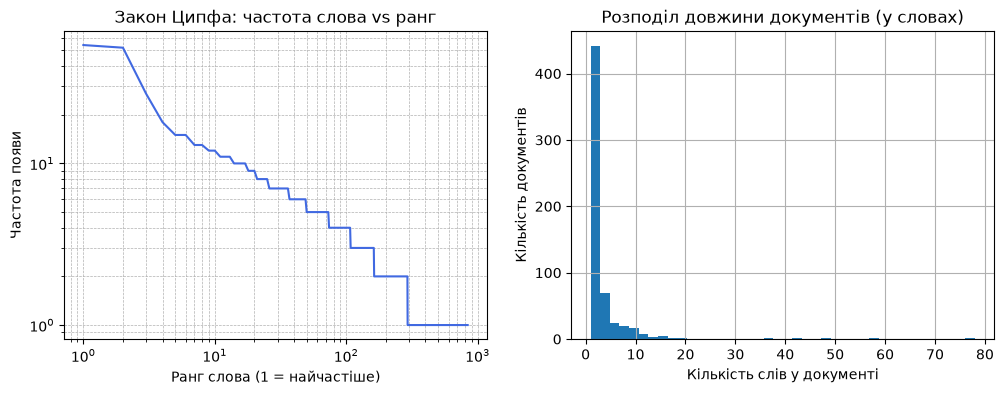

Документів з 1-3 слів: 490 з 591
Слів, що зустрілися лише один раз: 547 з 839


In [118]:
word_freqs = np.array(sorted(counter.values(), reverse=True))
ranks = np.arange(1, len(word_freqs) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.loglog(ranks, word_freqs, color='royalblue')
plt.title("Закон Ципфа: частота слова vs ранг")
plt.xlabel("Ранг слова (1 = найчастіше)")
plt.ylabel("Частота появи")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
plt.hist(lengths, bins=40)
plt.title("Розподіл довжини документів (у словах)")
plt.xlabel("Кількість слів у документі")
plt.ylabel("Кількість документів")
plt.grid()

plt.show()

print("Документів з 1-3 слів:", int(np.sum(np.array(lengths) <= 3)), "з", len(lengths))
print("Слів, що зустрілися лише один раз:", sum(1 for w in counter if counter[w] == 1), "з", len(counter))

##### Як читати ці два графіки

__Лівий графік (закон Ципфа).__ По горизонталі ранг слова, по вертикалі кількість появ, обидві осі логарифмічні. Для природної мови це майже пряма спадна лінія: кілька десятків слів зустрічаються часто, а далі йде величезний хвіст слів, що трапляються один-два рази (таких близько 600 із 839).

Це і є головна проблема підходу «а»: щоб вивчити осмислений вектор слова, мережа мусить побачити слово багато разів, а слово, яке зустрілося один раз, отримає вектор-шум.

__Правий графік.__ Майже всі документи мають 1-3 слова. Це визначає вибір `MAX_LEN` і означає, що рекурентна мережа тут майже нічого не обробляє.

In [119]:
specials = ["[PAD]", "[UNK]"]
most_common = counter.most_common()
itos = specials + [w for w, _ in most_common]
stoi = {}
for i in range(len(itos)):
    stoi[itos[i]] = i

PAD_IDX = stoi["[PAD]"]
UNK_IDX = stoi["[UNK]"]
vocab_size = len(stoi)

print("Розмір словника:", vocab_size)
print("Приклад індексу:", stoi.get("funny", UNK_IDX))

Розмір словника: 841
Приклад індексу: 19


In [120]:
MAX_LEN = 16


def encode(tokens):
    result = []
    for t in tokens:
        result.append(stoi.get(t, UNK_IDX))
    return result


def pad_sequence(seq):
    seq = seq[:MAX_LEN] + [PAD_IDX] * max(0, MAX_LEN - len(seq))
    return torch.tensor(seq, dtype=torch.long)


def make_tensors(tok_lists, label_list):
    X = torch.stack([pad_sequence(encode(t)) for t in tok_lists])
    y = torch.tensor(label_list, dtype=torch.long)
    return X, y


X_train_txt, y_train_txt = make_tensors(train_tokens, train_labels)
X_val_txt, y_val_txt = make_tensors(val_tokens, val_labels)
X_test_txt, y_test_txt = make_tensors(test_tokens, test_labels)

print(X_train_txt.shape, X_val_txt.shape, X_test_txt.shape)
print(X_train_txt[0])

torch.Size([591, 16]) torch.Size([148, 16]) torch.Size([317, 16])
tensor([294,  27, 295,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0])


In [121]:
train_loader_txt = DataLoader(TensorDataset(X_train_txt, y_train_txt), batch_size=32, shuffle=True)
val_loader_txt = DataLoader(TensorDataset(X_val_txt, y_val_txt), batch_size=32, shuffle=False)
test_loader_txt = DataLoader(TensorDataset(X_test_txt, y_test_txt), batch_size=32, shuffle=False)

for xb, yb in train_loader_txt:
    print(xb.shape, yb.shape)
    break

torch.Size([32, 16]) torch.Size([32])


##### Словник, індекси та padding

`itos` це список слів, де позиція і є індексом, `stoi` зворотний словник. Додано два службові токени: `[PAD]` з індексом 0 для заповнення коротких послідовностей і `[UNK]` з індексом 1 для слів, яких не було у тренувальному словнику. Разом 841 токен.

`encode` замінює слова на номери, `pad_sequence` обрізає задовге й доповнює закоротке нулями, бо батч подається в мережу прямокутним тензором. `MAX_LEN=16` покриває приблизно 99% документів.

Застереження: `padding_idx` гарантує, що `[PAD]` має нульовий вектор, але LSTM усе одно робить крок для кожної з 16 позицій, і фінальний прихований стан формується після проходу через 13-14 порожніх позицій. У довгих текстах це дрібниця, а тут може псувати сигнал, і правильніше було б узяти `pack_padded_sequence`.

In [122]:
class BiLSTM_Genre(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, pad_idx, num_classes, num_layers=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)

        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        x = self.embedding(x)

        out, (h, c) = self.lstm(x)
        h_fwd = h[-2, :, :]
        h_bwd = h[-1, :, :]
        h_cat = torch.cat([h_fwd, h_bwd], dim=1)

        logits = self.fc(h_cat)
        return logits

##### Архітектура: Embedding + BiLSTM

__Embedding-шар.__ Це таблиця 841 x 100: кожному слову відповідає вектор зі 100 чисел. Якби ми подали просто номер слова, мережа вважала б, що слово з номером 7 «більше» за слово з номером 6, хоча порядок у словнику довільний. Embedding дає щільний вектор у просторі, де відстань має зміст.

__LSTM.__ Рекурентна мережа обробляє послідовність крок за кроком і передає сама собі внутрішній стан, тобто має пам'ять про попередні слова. Проста RNN при розгортанні в часі забуває початок послідовності через затухання градієнтів, а LSTM вирішує це двома станами пам'яті: довготривалим `c`, який змінюється лише трохи, і короткочасним `h`. Керують цим три вентилі на сигмоїдах: forget gate вирішує, що викинути з пам'яті, input gate що додати, output gate що видати назовні.

__Двонапрямленість.__ Два LSTM: один читає текст зліва направо, другий справа наліво. Їхні фінальні стани склеюються, тому вихідний шар має `hidden_dim * 2` входів і 3 виходи.

In [123]:
emb_dim = 100
hidden_dim = 64
num_classes = 3

torch.manual_seed(10)
model_rand = BiLSTM_Genre(vocab_size, emb_dim, hidden_dim, PAD_IDX, num_classes).to(device)
print(model_rand)

print("Усього параметрів:", sum(p.numel() for p in model_rand.parameters()))
print("з них в Embedding:", model_rand.embedding.weight.numel())
print("Тренувальних документів:", len(train_texts))

BiLSTM_Genre(
  (embedding): Embedding(841, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)
Усього параметрів: 169479
з них в Embedding: 84100
Тренувальних документів: 591


##### Скільки параметрів і скільки даних

У моделі 169 479 параметрів, з яких 84 100 припадає на Embedding, а тренувальних документів лише 591, і в кожному в середньому 3 слова. Тобто мережа має вивчити значення слів, маючи у 48 разів менше слововживань, ніж параметрів.

In [124]:
criterion_txt = nn.CrossEntropyLoss()
optimizer_rand = torch.optim.Adam(model_rand.parameters(), lr=1e-3)

n_epochs = 30

rand_train_loss = []
rand_val_loss = []
rand_train_acc = []
rand_val_acc = []

best_val_loss = float('inf')
best_epoch = 0

for epoch in range(n_epochs):
    tl = train_one_epoch(model_rand, train_loader_txt, optimizer_rand, criterion_txt, device)
    vl = evaluate_one_epoch(model_rand, val_loader_txt, criterion_txt, device)
    ta = evaluate_accuracy(model_rand, train_loader_txt, device)
    va = evaluate_accuracy(model_rand, val_loader_txt, device)

    rand_train_loss.append(tl)
    rand_val_loss.append(vl)
    rand_train_acc.append(ta)
    rand_val_acc.append(va)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(model_rand.state_dict(), 'lstm_rand_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f} | train_acc={ta:.4f} | val_acc={va:.4f}")

print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
model_rand.load_state_dict(torch.load('lstm_rand_best.pth'))

[01] train_loss=1.0091 | val_loss=0.8585 | train_acc=0.6447 | val_acc=0.6419
[02] train_loss=0.7833 | val_loss=0.7380 | train_acc=0.6430 | val_acc=0.6419
[03] train_loss=0.7285 | val_loss=0.7189 | train_acc=0.6836 | val_acc=0.6419
[04] train_loss=0.6767 | val_loss=0.6962 | train_acc=0.7208 | val_acc=0.6757
[05] train_loss=0.6158 | val_loss=0.6936 | train_acc=0.8122 | val_acc=0.6824
[06] train_loss=0.5397 | val_loss=0.6604 | train_acc=0.8359 | val_acc=0.6959
[07] train_loss=0.4552 | val_loss=0.6790 | train_acc=0.8511 | val_acc=0.6757
[08] train_loss=0.3938 | val_loss=0.7067 | train_acc=0.8765 | val_acc=0.6959
[09] train_loss=0.3385 | val_loss=0.7697 | train_acc=0.9019 | val_acc=0.6622
[10] train_loss=0.2792 | val_loss=0.7878 | train_acc=0.9002 | val_acc=0.6824
[11] train_loss=0.2496 | val_loss=0.9126 | train_acc=0.9171 | val_acc=0.6284
[12] train_loss=0.2209 | val_loss=0.9602 | train_acc=0.9222 | val_acc=0.6284
[13] train_loss=0.2165 | val_loss=0.9533 | train_acc=0.9255 | val_acc=0.6351

<All keys matched successfully>

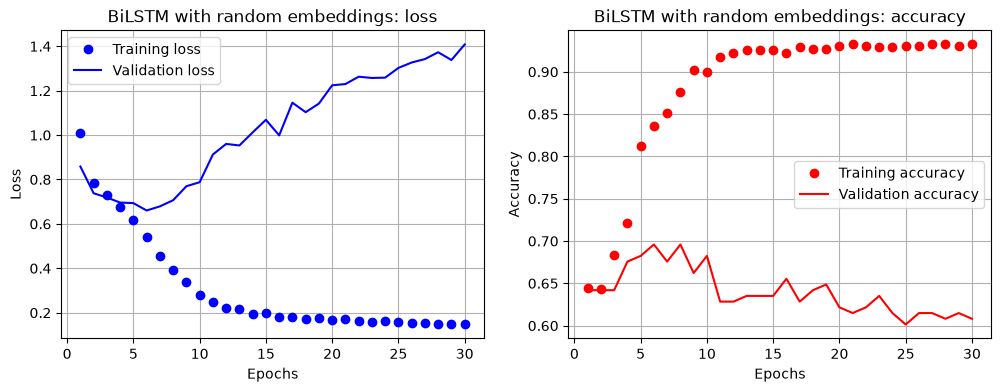

In [125]:
plot_curves(rand_train_loss, rand_val_loss, rand_train_acc, rand_val_acc,
            "BiLSTM with random embeddings")

In [126]:
rand_true, rand_pred = predict_all(model_rand, test_loader_txt, device)

rand_acc = accuracy_score(rand_true, rand_pred)
rand_f1 = f1_score(rand_true, rand_pred, average='macro')

print("Random embeddings: test accuracy", round(rand_acc, 4), "| macro F1", round(rand_f1, 4))
print(confusion_matrix(rand_true, rand_pred))
print(classification_report(rand_true, rand_pred, target_names=label_names, digits=4, zero_division=0))

Random embeddings: test accuracy 0.6972 | macro F1 0.4211
[[ 35  63   1]
 [ 16 186   1]
 [  0  15   0]]
              precision    recall  f1-score   support

      Comedy     0.6863    0.3535    0.4667        99
       Drama     0.7045    0.9163    0.7966       203
      Horror     0.0000    0.0000    0.0000        15

    accuracy                         0.6972       317
   macro avg     0.4636    0.4233    0.4211       317
weighted avg     0.6655    0.6972    0.6559       317



##### Підхід «а»: випадкові embeddings. Результат

Learning curves показують перенавчання в чистому вигляді: валідаційна втрата досягає мінімуму вже на 3-5 епосі й далі зростає, тоді як тренувальна продовжує падати. Це найшвидше перенавчання в роботі.

Accuracy треба порівнювати не з нулем, а з 0.6404, тобто з тривіальною моделью. А macro-F1 ставить остаточний діагноз: низьке значення означає, що два менших класи практично не розпізнаються, і матриця помилок це підтверджує.

Отже, модель вивчила не зв'язок «теги -> жанр», а розподіл класів.

##### Завантаження GloVe

Були версії на 50, 100, 200 та 300 чисел на слово. Взято 100, бо саме така розмірність Embedding у моделі «а», тому відрізняється лише спосіб ініціалізації ваг, а не розмір мережі.

In [127]:
def load_glove_txt(path):
    vectors = {}
    with open(path, "r", encoding="utf8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            word = parts[0]
            vec = np.asarray(parts[1:], dtype=np.float32)
            vectors[word] = vec
    dim = len(next(iter(vectors.values())))
    return vectors, dim


glove, glove_dim = load_glove_txt('glove.6B.100d.txt')
print("GloVe dim:", glove_dim, "| entries:", len(glove))

for w in ["funny", "zombie", "war", "disney"]:
    print(w, glove[w][:8])

GloVe dim: 100 | entries: 400000
funny [ 0.17602  0.20096  0.32335 -0.90513 -0.41095  0.56988  0.12624  0.54167]
zombie [-0.33894  0.29189  0.29925 -0.65192 -0.45548  0.88613 -0.49327 -0.87819]
war [-0.39505  1.0285  -0.21556  0.36596 -0.34455 -0.23504 -0.18961 -0.81103]
disney [ 0.84716 -0.86189  0.47401  0.3026   0.62371 -0.42793 -0.19292 -0.19037]


In [128]:
emb_matrix = np.random.normal(scale=0.1, size=(vocab_size, glove_dim)).astype(np.float32)
emb_matrix[PAD_IDX] = 0.0

hit = 0
missing = []
for w, idx in stoi.items():
    v = glove.get(w)
    if v is not None:
        emb_matrix[idx] = v
        hit += 1
    elif w not in specials:
        missing.append(w)

print(f"Coverage: {hit}/{vocab_size} = {hit/vocab_size:.1%}")
print("Слова, яких немає в GloVe:", missing[:20])

Coverage: 831/841 = 98.8%
Слова, яких немає в GloVe: ['mindfuck', 'rasicm', 'palahnuik', 'boksdrama', 'clousseau', 'naivity', 'wapendrama', 'happpiness']


##### GloVe

GloVe це готові вектори слів, натреновані на корпусі з 6 мільярдів слів: 400 000 слів по 100 чисел. Принцип: значення слова визначається його контекстом, тому слова зі схожим оточенням отримують схожі вектори. Через це `funny` виявляється близько до `comedy`, а `zombie` близько до `vampire`, хоча явно це ніхто не програмував. Це той самий transfer learning, що MobileNet у частині 2, тільки для слів.

Матриця під наш словник збирається так: спочатку малі випадкові числа (для слів, яких у GloVe немає), рядок `[PAD]` обнуляється, а потім підставляються вектори з GloVe. Покриття виходить 98.8% завдяки тому, що `clean_text` уже привів усе до нижнього регістру; не знайшлися лише 8 слів, і це друкарські помилки та перекручені прізвища.

In [129]:
torch.manual_seed(10)
model_glove = BiLSTM_Genre(vocab_size, glove_dim, hidden_dim, PAD_IDX, num_classes).to(device)

pretrained_emb = nn.Embedding.from_pretrained(
    torch.tensor(emb_matrix),
    freeze=True,
    padding_idx=PAD_IDX
).to(device)

model_glove.embedding = pretrained_emb

print("Усього параметрів:", sum(p.numel() for p in model_glove.parameters()))
print("Тренувальних параметрів:", sum(p.numel() for p in model_glove.parameters() if p.requires_grad))

Усього параметрів: 169479
Тренувальних параметрів: 85379


##### Підстановка GloVe в Embedding-шар

`freeze=True` означає, що ці ваги не оновлюються під час навчання. Результат видно по кількості параметрів: усього 169 479, а тренувальних лише 85 379, бо 84 100 параметрів Embedding зафіксовані й мережі залишається вивчити тільки LSTM та вихідний шар.

In [130]:
torch.manual_seed(10)
optimizer_glove = torch.optim.Adam(model_glove.parameters(), lr=1e-3)

glove_train_loss = []
glove_val_loss = []
glove_train_acc = []
glove_val_acc = []

best_val_loss = float('inf')
best_epoch = 0

for epoch in range(30):
    tl = train_one_epoch(model_glove, train_loader_txt, optimizer_glove, criterion_txt, device)
    vl = evaluate_one_epoch(model_glove, val_loader_txt, criterion_txt, device)
    ta = evaluate_accuracy(model_glove, train_loader_txt, device)
    va = evaluate_accuracy(model_glove, val_loader_txt, device)

    glove_train_loss.append(tl)
    glove_val_loss.append(vl)
    glove_train_acc.append(ta)
    glove_val_acc.append(va)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(model_glove.state_dict(), 'lstm_glove_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f} | train_acc={ta:.4f} | val_acc={va:.4f}")

print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
model_glove.load_state_dict(torch.load('lstm_glove_best.pth'))

[01] train_loss=0.9772 | val_loss=0.8261 | train_acc=0.6379 | val_acc=0.6419
[02] train_loss=0.7838 | val_loss=0.7483 | train_acc=0.6430 | val_acc=0.6419
[03] train_loss=0.7268 | val_loss=0.7175 | train_acc=0.6667 | val_acc=0.6757
[04] train_loss=0.6842 | val_loss=0.6902 | train_acc=0.7411 | val_acc=0.7365
[05] train_loss=0.6413 | val_loss=0.6837 | train_acc=0.7547 | val_acc=0.7432
[06] train_loss=0.6076 | val_loss=0.6901 | train_acc=0.7513 | val_acc=0.7432
[07] train_loss=0.5807 | val_loss=0.6760 | train_acc=0.7783 | val_acc=0.7365
[08] train_loss=0.5333 | val_loss=0.6815 | train_acc=0.7834 | val_acc=0.7365
[09] train_loss=0.5158 | val_loss=0.6888 | train_acc=0.8037 | val_acc=0.7432
[10] train_loss=0.4789 | val_loss=0.6937 | train_acc=0.8071 | val_acc=0.7432
[11] train_loss=0.4436 | val_loss=0.7459 | train_acc=0.8325 | val_acc=0.6959
[12] train_loss=0.4398 | val_loss=0.7072 | train_acc=0.8409 | val_acc=0.7027
[13] train_loss=0.4060 | val_loss=0.7120 | train_acc=0.8528 | val_acc=0.7297

<All keys matched successfully>

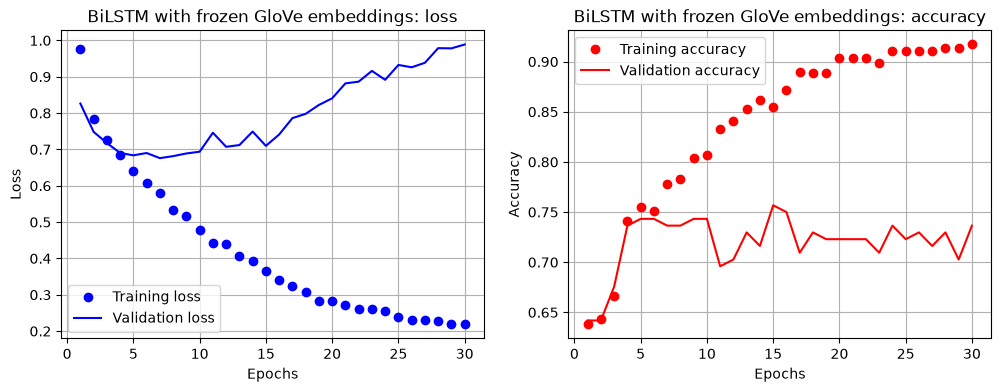

In [131]:
plot_curves(glove_train_loss, glove_val_loss, glove_train_acc, glove_val_acc,
            "BiLSTM with frozen GloVe embeddings")

In [132]:
glove_true, glove_pred = predict_all(model_glove, test_loader_txt, device)

glove_acc = accuracy_score(glove_true, glove_pred)
glove_f1 = f1_score(glove_true, glove_pred, average='macro')

print("GloVe frozen: test accuracy", round(glove_acc, 4), "| macro F1", round(glove_f1, 4))
print(confusion_matrix(glove_true, glove_pred))
print(classification_report(glove_true, glove_pred, target_names=label_names, digits=4, zero_division=0))

GloVe frozen: test accuracy 0.7192 | macro F1 0.4313
[[ 35  64   0]
 [ 10 193   0]
 [  3  12   0]]
              precision    recall  f1-score   support

      Comedy     0.7292    0.3535    0.4762        99
       Drama     0.7175    0.9507    0.8178       203
      Horror     0.0000    0.0000    0.0000        15

    accuracy                         0.7192       317
   macro avg     0.4822    0.4348    0.4313       317
weighted avg     0.6872    0.7192    0.6724       317



##### Підхід «б»: GloVe. Результат

Learning curves кращі, але не в тому, в чому можна було очікувати. Сам мінімум валідаційної втрати вийшов приблизно таким самим, як у моделі «а», і настав майже на тій самій епосі. Різниця в тому, __що відбувається після мінімуму__: у моделі «а» втрата після нього зростає різко, а з GloVe піднімається значно повільніше, тому до 30-ї епохи розрив між двома кривими стає великим. Тобто GloVe не стільки прискорює навчання, скільки стримує перенавчання.

На тесті accuracy вища, а от macro-F1 піднялася лише трохи. Матриця помилок показує, чому: приріст accuracy отримано за рахунок того, що модель ще краще вгадує Drama, тоді як Horror вона не знаходить взагалі (recall 0). Тобто розрізняти всі три класи модель так і не навчилася.

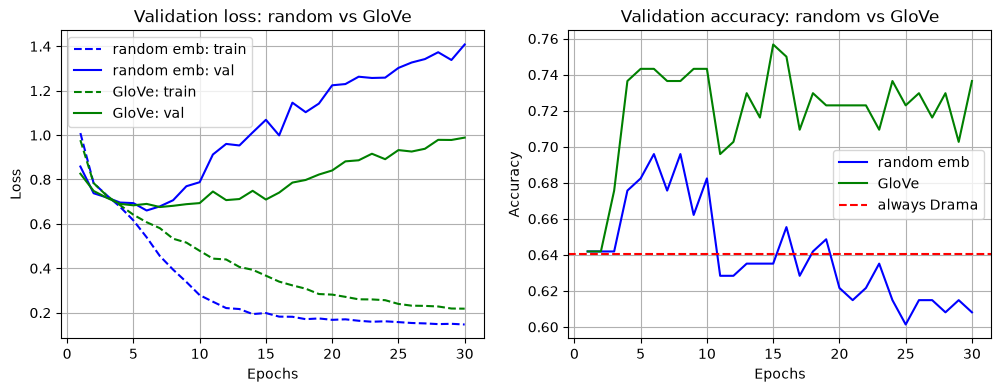

In [133]:
epochs_rand = range(1, len(rand_val_loss) + 1)
epochs_glove = range(1, len(glove_val_loss) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_rand, rand_train_loss, 'b--', label='random emb: train')
plt.plot(epochs_rand, rand_val_loss, 'b', label='random emb: val')
plt.plot(epochs_glove, glove_train_loss, 'g--', label='GloVe: train')
plt.plot(epochs_glove, glove_val_loss, 'g', label='GloVe: val')
plt.title('Validation loss: random vs GloVe')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epochs_rand, rand_val_acc, 'b', label='random emb')
plt.plot(epochs_glove, glove_val_acc, 'g', label='GloVe')
plt.axhline(0.6404, color='red', linestyle='--', label='always Drama')
plt.title('Validation accuracy: random vs GloVe')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

##### Порівняльні графіки

__Ліва панель (втрати).__ Пунктир це train, суцільна лінія validation, синє це випадкові embeddings, зелене GloVe. Тут важливими є три речі: де розвертається кожна суцільна лінія, наскільки низько вона опускається та яка відстань між пунктиром і суцільною лінією того самого кольору (це міра перенавчання).

У цьому прогоні перші дві речі в обох моделей вийшли приблизно однаковими, а різниця видна саме в третій: синя пара розходиться набагато сильніше. Тобто внесок GloVe тут не в глибшому мінімумі, а в меншому перенавчанні, і це логічно, бо половина параметрів заморожена.

__Права панель.__ Червона лінія на 0.6404 це рівень тривіальної моделі, тобто точка відліку, а відстань між кривими і є внеском GloVe.

In [134]:
torch.manual_seed(10)
model_glove_ft = BiLSTM_Genre(vocab_size, glove_dim, hidden_dim, PAD_IDX, num_classes).to(device)
model_glove_ft.embedding = nn.Embedding.from_pretrained(
    torch.tensor(emb_matrix),
    freeze=False,
    padding_idx=PAD_IDX
).to(device)

optimizer_ft = torch.optim.Adam(model_glove_ft.parameters(), lr=1e-3)

ft_val_loss = []
best_val_loss = float('inf')
best_epoch = 0

for epoch in range(30):
    tl = train_one_epoch(model_glove_ft, train_loader_txt, optimizer_ft, criterion_txt, device)
    vl = evaluate_one_epoch(model_glove_ft, val_loader_txt, criterion_txt, device)
    ft_val_loss.append(vl)

    if vl < best_val_loss:
        best_val_loss = vl
        best_epoch = epoch + 1
        torch.save(model_glove_ft.state_dict(), 'lstm_glove_ft_best.pth')

    print(f"[{epoch+1:02d}] train_loss={tl:.4f} | val_loss={vl:.4f}")

print("Найкраща епоха:", best_epoch, "val_loss:", round(best_val_loss, 4))
model_glove_ft.load_state_dict(torch.load('lstm_glove_ft_best.pth'))

ft_true, ft_pred = predict_all(model_glove_ft, test_loader_txt, device)
ft_acc = accuracy_score(ft_true, ft_pred)
ft_f1 = f1_score(ft_true, ft_pred, average='macro')
print("GloVe fine-tuned: test accuracy", round(ft_acc, 4), "| macro F1", round(ft_f1, 4))

[01] train_loss=0.9936 | val_loss=0.8311
[02] train_loss=0.7710 | val_loss=0.7467
[03] train_loss=0.7129 | val_loss=0.7044
[04] train_loss=0.6515 | val_loss=0.6720
[05] train_loss=0.5931 | val_loss=0.6677
[06] train_loss=0.5231 | val_loss=0.6823
[07] train_loss=0.4601 | val_loss=0.7205
[08] train_loss=0.4163 | val_loss=0.6989
[09] train_loss=0.3674 | val_loss=0.7398
[10] train_loss=0.3146 | val_loss=0.7788
[11] train_loss=0.2820 | val_loss=0.7892
[12] train_loss=0.2564 | val_loss=0.8018
[13] train_loss=0.2287 | val_loss=0.8512
[14] train_loss=0.2126 | val_loss=0.9213
[15] train_loss=0.2073 | val_loss=0.9062
[16] train_loss=0.1969 | val_loss=0.9247
[17] train_loss=0.1809 | val_loss=0.9754
[18] train_loss=0.1749 | val_loss=1.0079
[19] train_loss=0.1710 | val_loss=1.0274
[20] train_loss=0.1680 | val_loss=1.0541
[21] train_loss=0.1618 | val_loss=1.1035
[22] train_loss=0.1646 | val_loss=1.1317
[23] train_loss=0.1565 | val_loss=1.1357
[24] train_loss=0.1597 | val_loss=1.1993
[25] train_loss=

##### Додатковий експеримент: чи варто донавчати GloVe

Тут `freeze=False`: вектори GloVe беруться як початкове значення, але далі оновлюються разом з мережею.

Результат виходить гіршим за заморожений GloVe, і найцікавіше, що найкраща епоха знову настає дуже рано, як у випадкових embeddings.

Причина: градієнтний спуск на 591 документі починає «розтягувати» вектори слів під ці конкретні приклади. Слово, яке зустрілося один раз, і то у фільмі жанру Drama, зсувається в бік Drama, хоча в GloVe воно стояло серед споріднених слів. Правило: чим менше власних даних, тим сильніше треба заморожувати запозичене.

                         Модель  Accuracy  macro F1 Найкраща епоха
0     Тривіальна (завжди Drama)    0.6404    0.2600              -
1  TF-IDF + Naive Bayes (lab 2)    0.7700    0.6600              -
2  BiLSTM, випадкові embeddings    0.6972    0.4211              6
3   BiLSTM + GloVe (заморожені)    0.7192    0.4313              7
4    BiLSTM + GloVe (донавчені)    0.7539    0.4700              5


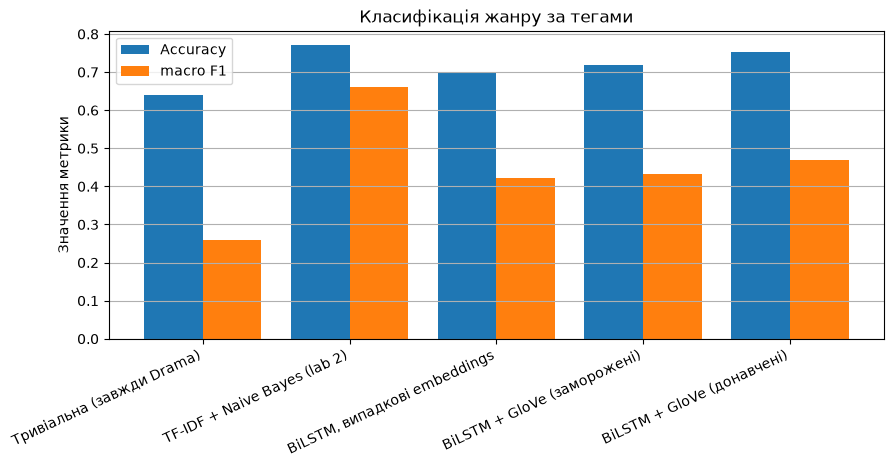

In [135]:
text_results = pd.DataFrame({
    'Модель': ['Тривіальна (завжди Drama)',
               'TF-IDF + Naive Bayes (lab 2)',
               'BiLSTM, випадкові embeddings',
               'BiLSTM + GloVe (заморожені)',
               'BiLSTM + GloVe (донавчені)'],
    'Accuracy': [0.6404, 0.77, round(rand_acc, 4), round(glove_acc, 4), round(ft_acc, 4)],
    'macro F1': [0.26, 0.66, round(rand_f1, 4), round(glove_f1, 4), round(ft_f1, 4)],
    'Найкраща епоха': ['-', '-',
                       int(np.argmin(rand_val_loss)) + 1,
                       int(np.argmin(glove_val_loss)) + 1,
                       int(np.argmin(ft_val_loss)) + 1]
})
print(text_results)

plt.figure(figsize=(10, 4))
x = np.arange(len(text_results))
plt.bar(x - 0.2, text_results['Accuracy'], width=0.4, label='Accuracy')
plt.bar(x + 0.2, text_results['macro F1'], width=0.4, label='macro F1')
plt.xticks(x, text_results['Модель'], rotation=25, ha='right')
plt.ylabel('Значення метрики')
plt.title('Класифікація жанру за тегами')
plt.legend()
plt.grid(axis='y')
plt.show()

##### Висновки частини 3

1. __Якість класифікації.__ Pretrained embeddings дали приріст accuracy, але macro-F1 піднялася лише трохи. Версія з випадковими embeddings обігнала тривіальну модель «завжди Drama» всього на кілька пунктів. Жодна з двох моделей не знайшла ні одного фільму класу Horror (recall 0), тому за macro-F1 обидві слабкі.

2. __Швидкість і стабільність навчання.__ Мінімум валідаційної втрати в обох моделей настав приблизно на одній епосі й виявився приблизно однаковим. Різниця в тому, що після мінімуму втрата з випадковими embeddings зростає різко, а з GloVe значно повільніше. Тобто GloVe тут стримує перенавчання, а не прискорює навчання.

3. __Чому GloVe допоміг саме так.__ Embedding містить 84 100 параметрів, а даних лише 591 документ по 3 слова, причому три чверті слів зустрічаються один раз. Вивчити значення слів із такої кількості прикладів неможливо, а заморожений GloVe і приносить ці значення готовими, і вдвічі зменшує кількість навчуваних параметрів, через що перенавчатися стає нічим.

4. __Донавчання embeddings тут не зашкодило, а навпаки.__ Варіант із `freeze=False` дав найкращий результат з трьох і за accuracy, і за macro-F1. Тобто правило «на малих даних запозичене треба заморожувати» на цих даних не підтвердилося. Водночас різниця між трьома підходами невелика, а вибірки крихітні (591 документ на навчання і лише 148 на валідацію, за якою вибирається епоха), тому надійно впорядкувати три підходи за одним запуском не можна: для цього потрібна перевірка на кількох сідах, як у частині 1.

5. __Головний висновок: найкраща нейронна мережа все одно програла простому Naive Bayes із лабораторної роботи 2__ (0.77 accuracy та 0.66 macro-F1), причому за macro-F1 з великим відривом. LSTM існує, щоб враховувати порядок слів («not funny at all» проти «funny»), а мої документи це 2-3 теги у довільному порядку. Порядку, який щось означає, тут немає, тому головна перевага LSTM не дає нічого, а недоліки залишаються: багато параметрів, перенавчання на 591 прикладі та псування сигналу padding-ом. Naive Bayes навпаки відповідає структурі даних: порядок ігнорується за побудовою, а рідкісні характерні слова отримують велику вагу через IDF.

Отже, складніша модель не є кращою сама по собі. Наступним кроком була б не складніша рекурентна архітектура, а відмова від рекурентності: усереднення GloVe-векторів документа з повнозв'язаним шаром поверх.

# Загальні висновки лабораторної роботи

In [136]:
final_summary = pd.DataFrame({
    'Частина': ['1. Табличні дані', '1. Табличні дані',
                '2. Зображення', '2. Зображення',
                '3. Текст', '3. Текст', '3. Текст'],
    'Модель': ['Random Forest (lab 1)', 'MLP (lab 3)',
               'CNN з нуля', 'MobileNetV2 pretrained',
               'TF-IDF + Naive Bayes (lab 2)', 'BiLSTM випадкові emb', 'BiLSTM + GloVe'],
    'Метрика': [0.967, round(mlp_acc, 3),
                round(cnn_acc, 3), round(mob_acc, 3),
                0.770, round(rand_acc, 3), round(glove_acc, 3)],
    'Тип': ['класичний', 'нейромережа',
            'нейромережа', 'нейромережа + transfer',
            'класичний', 'нейромережа', 'нейромережа + transfer']
})
print(final_summary.to_string(index=False))

         Частина                       Модель  Метрика                    Тип
1. Табличні дані        Random Forest (lab 1)    0.967              класичний
1. Табличні дані                  MLP (lab 3)    0.956            нейромережа
   2. Зображення                   CNN з нуля    0.737            нейромережа
   2. Зображення       MobileNetV2 pretrained    0.832 нейромережа + transfer
        3. Текст TF-IDF + Naive Bayes (lab 2)    0.770              класичний
        3. Текст         BiLSTM випадкові emb    0.697            нейромережа
        3. Текст               BiLSTM + GloVe    0.719 нейромережа + transfer


##### Підсумок

| Частина | Нейромережа | Класичний метод |
|---|---|---|
| 1. Таблиця, 87 готових ознак | MLP | Random Forest: 0.967 |
| 2. Зображення, сирі пікселі | CNN з нуля проти pretrained MobileNetV2 | непридатні |
| 3. Текст, 2-3 невпорядкованих теги | BiLSTM з випадковими embeddings проти GloVe | Naive Bayes: 0.770 |

1. __Нейронні мережі перемогли в одній задачі з трьох__ — саме там, де на вході були сирі пікселі й ознаки треба було побудувати. Де ознаки вже побудовані людиною (частина 1) або де структура даних не відповідає архітектурі (частина 3), класичні методи виявилися не гіршими й дешевшими.

2. __Виграє та модель, чиї вбудовані припущення збігаються з реальністю.__ Дерево припускає пороги по ознаках, і для фішингового датасету це правда. CNN припускає локальні шаблони, однакові в будь-якій частині входу, і для зображень це правда. LSTM припускає, що важливий порядок елементів, і для тегів це неправда.

3. __Перенавчання було в усіх трьох частинах, і learning curves були єдиним способом його побачити.__ У частині 1 воно не помітне по accuracy, лише по втраті. У частині 2 валідаційна крива була настільки нестабільною, що без early stopping ми взяли б гіршу модель. У частині 3 перенавчання наставало за кілька епох.

4. __Найбільший приріст дало не проектування архітектури, а transfer learning__ (ImageNet-ознаки для зображень і вектори GloVe для слів). При цьому ефект від заморожування виявився різним: у частині 2 заморожена згорткова частина повністю зняла перенавчання, а в частині 3 заморожений і донавчений GloVe дали близькі результати, тобто просте правило «запозичене завжди треба заморожувати» на моїх текстових даних не підтвердилося.

5. __Метрика визначає висновок.__ У частині 3 модель із випадковими embeddings мала accuracy, близьку до частки найбільшого класу, і жодна з текстових моделей не знайшла ні одного фільму класу Horror. Побачити це можна було лише за macro-F1 та матрицею помилок, а не за accuracy.

6. __Один запуск нічого не доводить.__ У частині 1 перевірка на п'яти сідах дала розкид близько 0.4 відсоткового пункта, тобто різниці, менші за нього, обговорювати не можна. У частині 3 вибірки ще менші (591 документ на навчання і 148 на валідацію), тому там порядок трьох підходів за одним запуском теж не можна вважати надійним.

__Обмеження роботи.__ Фішинговий датасет штучно збалансований 50/50, тоді як у реальності фішинг рідкісний. Фотографії сміття зняті в лабораторних умовах. У частині 2 не застосована аугментація даних, а MobileNet не довчена: мінімум валідаційної втрати припав на останню епоху. У частині 3 в тесті лише 15 документів класу Horror.